# Modularity on the Karate Club Graph
### DSC212: Graph Theory — Research Assignment
**Name:** T Prem   **RollNo:** IMS25217

**Goal.** Implement the *spectral modularity* method **from scratch** (NumPy + NetworkX only), apply it recursively to Zachary's Karate Club network, visualise every split, track four node-level metrics (degree, betweenness, closeness, clustering) across the splits, and discuss what the numbers tell us about community structure.

**Method attribution.** The modularity objective, the modularity matrix $B$ and the leading-eigenvector bipartition follow M. E. J. Newman, *"Modularity and community structure in networks"*, PNAS **103**(23):8577–8582 (2006). The Karate Club data are from W. W. Zachary, *"An information flow model for conflict and fission in small groups"*, J. Anthropological Research **33**(4):452–473 (1977).

**How to run.** `Kernel → Restart & Run All`. The notebook needs only `numpy`, `pandas`, `matplotlib` and `networkx`; every random choice is seeded, so results are reproducible. No manual edits are needed.

---
## Contents
| Part | Topic |
|---|---|
| 0 | Setup and helper functions |
| 1 | The data: Zachary's Karate Club (exploration, ground truth) |
| 2 | The modularity matrix $B$ (null model, properties, spectrum) |
| 3 | The modularity score $Q$ — why *cut size* alone fails, and a random baseline |
| 4 | Spectral bipartition (leading eigenvector, sign rounding, threshold sweep, refinement) |
| 5 | Recursive spectral bisection (pseudocode → implementation → split log) |
| 6 | Visualisation after every split |
| 7 | A closer look at the $\Delta Q$ identity and the stopping rule |
| 8 | Node metrics after every split (4 metrics × every iteration) |
| 9 | Evolution plots, top-$k$ stability, rank correlations |
| 10 | How community structure shapes the metrics (participation, coverage, global vs. local) |
| 11 | Comparison with other community-detection algorithms |
| 12 | The same algorithm on other graphs (examples and sanity checks) |
| 13 | Discussion |
| 14 | Concept check (exam-style questions) and references |

## Part 0 — Setup and helper functions

In [ ]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt, matplotlib as mpl
from matplotlib.patches import Patch

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

SEED = 7                                   # one seed for layouts / randomised algorithms
PALETTE = list(plt.cm.tab10.colors)        # community id -> colour (stable across iterations)
print("numpy", np.__version__, "| networkx", nx.__version__, "| pandas", pd.__version__, "| matplotlib", mpl.__version__)

numpy 2.4.6 | networkx 3.7 | pandas 2.2.3 | matplotlib 3.10.0


In [ ]:
def draw_partition(G, pos, labels, ax, title="", node_scale=35, base=110, show_cut=True,
                   highlight=None, font_size=8):
    # Draw graph with a FIXED layout `pos`. Node colour = community id, size ~ degree,
    # red dashed edges = edges that cross communities, thick red ring = highlighted nodes.
    labels = np.asarray(labels)
    deg = dict(G.degree())
    nodes = list(G.nodes())
    cols = [PALETTE[labels[v] % len(PALETTE)] for v in nodes]
    sizes = [base + node_scale * deg[v] for v in nodes]
    cut = [(u, v) for u, v in G.edges() if labels[u] != labels[v]]
    inn = [(u, v) for u, v in G.edges() if labels[u] == labels[v]]
    nx.draw_networkx_edges(G, pos, edgelist=inn, ax=ax, alpha=0.35, width=1.0)
    if show_cut:
        nx.draw_networkx_edges(G, pos, edgelist=cut, ax=ax, alpha=0.65, width=1.2,
                               style="dashed", edge_color="crimson")
    ec = ["red" if (highlight is not None and v in highlight) else "black" for v in nodes]
    lw = [3.0 if (highlight is not None and v in highlight) else 0.8 for v in nodes]
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_color=cols, node_size=sizes,
                           edgecolors=ec, linewidths=lw, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=font_size, ax=ax)
    ax.set_title(title, fontsize=11); ax.set_axis_off()

def community_legend(labels, ax, loc="lower left"):
    labels = np.asarray(labels)
    handles = [Patch(facecolor=PALETTE[c % len(PALETTE)], edgecolor="k",
                     label=f"community {c}  (n={int((labels == c).sum())})") for c in np.unique(labels)]
    ax.legend(handles=handles, loc=loc, fontsize=8, frameon=True)

def labels_from_communities(comms, n):
    lab = np.zeros(n, dtype=int)
    for i, c in enumerate(comms):
        for v in c: lab[v] = i
    return lab
print("helpers ready")

helpers ready


## Part 1 — The data: Zachary's Karate Club

Zachary observed 34 members of a university karate club for two years. An edge links two members who interacted frequently *outside* class. During the study the instructor (**"Mr. Hi"**, node 0) and the administrator (**"John A."**, node 33) fell out over fees, and the club split in two. Because the network was recorded *before* the split, we can ask whether a purely structural method recovers the faction each member joined.

> **Indexing note.** NetworkX numbers the members `0…33`; Zachary's paper numbers them `1…34`. Node `0` = Mr. Hi = Zachary's member 1; node `33` = the administrator = Zachary's member 34.

We first build the objects used throughout: the adjacency matrix $A$, the degree vector $k$, the number of edges $m$ and the ground-truth faction vector.

In [ ]:
G = nx.karate_club_graph()
n, m = G.number_of_nodes(), G.number_of_edges()
nodes = list(range(n))
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)     # strictly 0/1 adjacency
k = A.sum(axis=1)                                          # degree vector
assert np.allclose(A, A.T) and set(np.unique(A)) <= {0.0, 1.0}
assert k.sum() == 2 * m

faction_name = np.array([G.nodes[i]["club"] for i in nodes])   # 'Mr. Hi' or 'Officer'
truth = np.where(faction_name == "Mr. Hi", 1, -1)              # +1 / -1 label vector s
truth_labels = np.where(truth == 1, 0, 1)                      # 0 / 1 community ids
pos = nx.spring_layout(G, seed=SEED, iterations=300)           # FIXED layout used everywhere

same = np.array([truth_labels[u] == truth_labels[v] for u, v in G.edges()])
stats = pd.Series({
    "nodes n": n, "edges m": m, "sum of degrees (=2m)": int(k.sum()),
    "density": round(nx.density(G), 4), "mean degree": round(k.mean(), 3),
    "max degree (node)": f"{int(k.max())} (node {int(k.argmax())})",
    "2nd max degree (node)": f"{int(np.sort(k)[-2])} (node {int(np.argsort(k)[-2])})",
    "min degree": int(k.min()), "# degree-1 nodes": int((k == 1).sum()),
    "diameter": nx.diameter(G), "avg shortest path": round(nx.average_shortest_path_length(G), 3),
    "avg clustering": round(nx.average_clustering(G), 3), "transitivity": round(nx.transitivity(G), 3),
    "degree assortativity": round(nx.degree_assortativity_coefficient(G), 3),
    "# triangles": sum(nx.triangles(G).values()) // 3,
    "|Mr. Hi faction|": int((truth == 1).sum()), "|Officer faction|": int((truth == -1).sum()),
    "edges inside Mr. Hi": int(sum(1 for (u, v), s in zip(G.edges(), same) if s and truth_labels[u] == 0)),
    "edges inside Officer": int(sum(1 for (u, v), s in zip(G.edges(), same) if s and truth_labels[u] == 1)),
    "edges between factions": int((~same).sum()),
})
print(stats.to_string())

nodes n                             34
edges m                             78
sum of degrees (=2m)               156
density                          0.139
mean degree                      4.588
max degree (node)         17 (node 33)
2nd max degree (node)      16 (node 0)
min degree                           1
# degree-1 nodes                     1
diameter                             5
avg shortest path                2.408
avg clustering                   0.571
transitivity                     0.256
degree assortativity            -0.476
# triangles                         45
|Mr. Hi faction|                    17
|Officer faction|                   17
edges inside Mr. Hi                 35
edges inside Officer                32
edges between factions              11


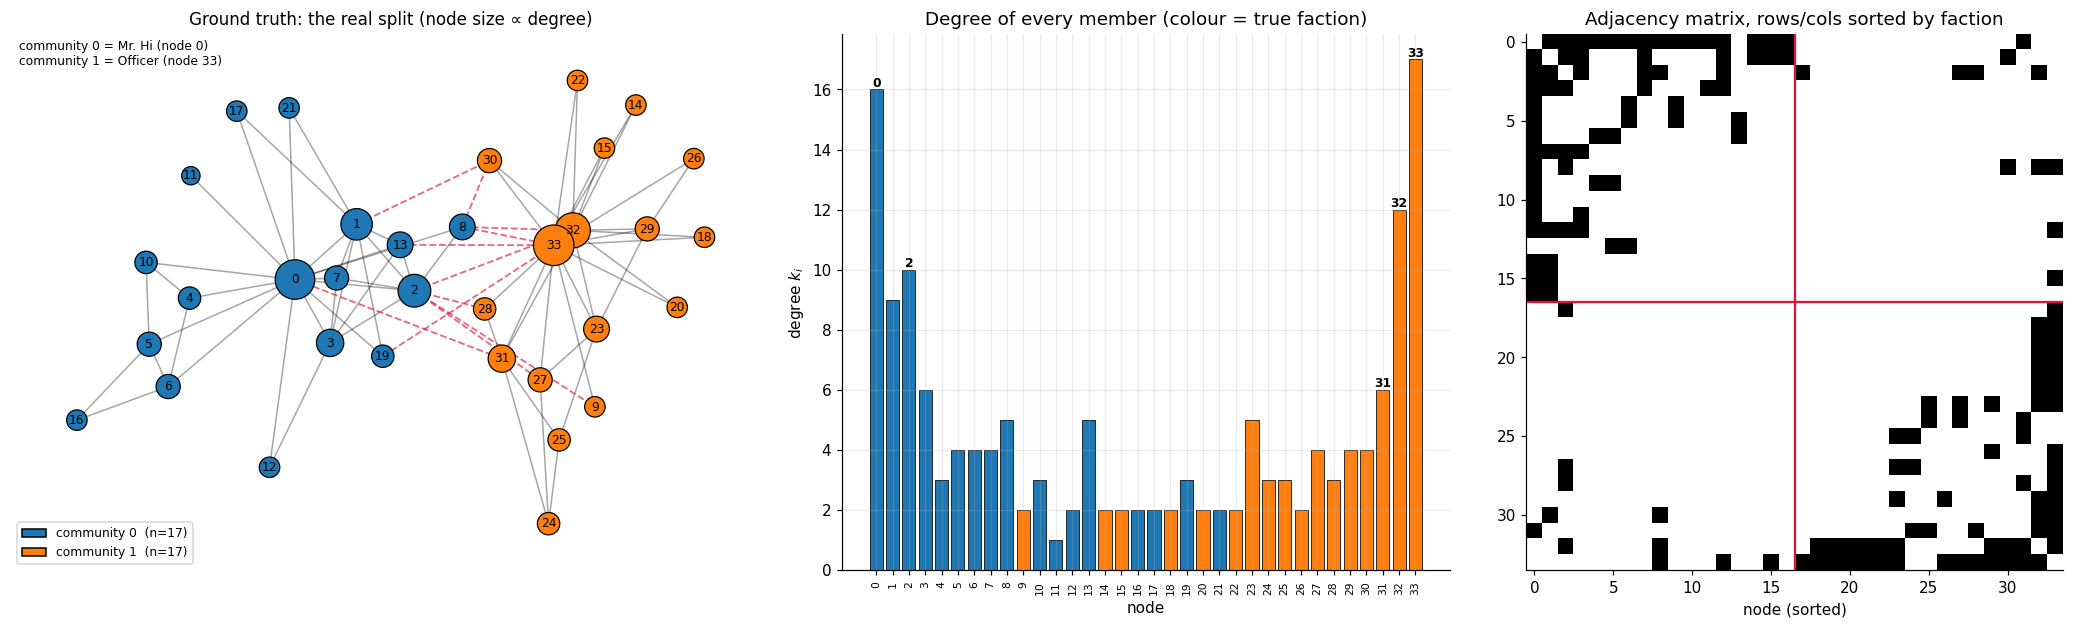

In [ ]:
order = np.argsort(truth_labels, kind="stable")          # nodes sorted by faction -> block structure
fig, axs = plt.subplots(1, 3, figsize=(19, 5.8), gridspec_kw={"width_ratios": [1.25, 1.0, 0.9]})
draw_partition(G, pos, truth_labels, axs[0], "Ground truth: the real split (node size ∝ degree)")
community_legend(truth_labels, axs[0])
axs[0].text(0.01, 0.99, "community 0 = Mr. Hi (node 0)\ncommunity 1 = Officer (node 33)", transform=axs[0].transAxes,
            va="top", fontsize=8)

axs[1].bar(nodes, k, color=[PALETTE[c] for c in truth_labels], edgecolor="k", lw=.5)
axs[1].set_xticks(nodes); axs[1].set_xticklabels(nodes, fontsize=7, rotation=90)
axs[1].set_xlabel("node"); axs[1].set_ylabel("degree $k_i$"); axs[1].set_title("Degree of every member (colour = true faction)")
for v in (0, 33, 32, 2, 31): axs[1].annotate(str(v), (v, k[v]), ha="center", va="bottom", fontsize=8, fontweight="bold")

axs[2].imshow(A[np.ix_(order, order)], cmap="Greys", interpolation="nearest"); axs[2].grid(False)
nb = int((truth_labels == 0).sum()); axs[2].axhline(nb - .5, c="crimson"); axs[2].axvline(nb - .5, c="crimson")
axs[2].set_title("Adjacency matrix, rows/cols sorted by faction"); axs[2].set_xlabel("node (sorted)")
plt.tight_layout(); plt.show()

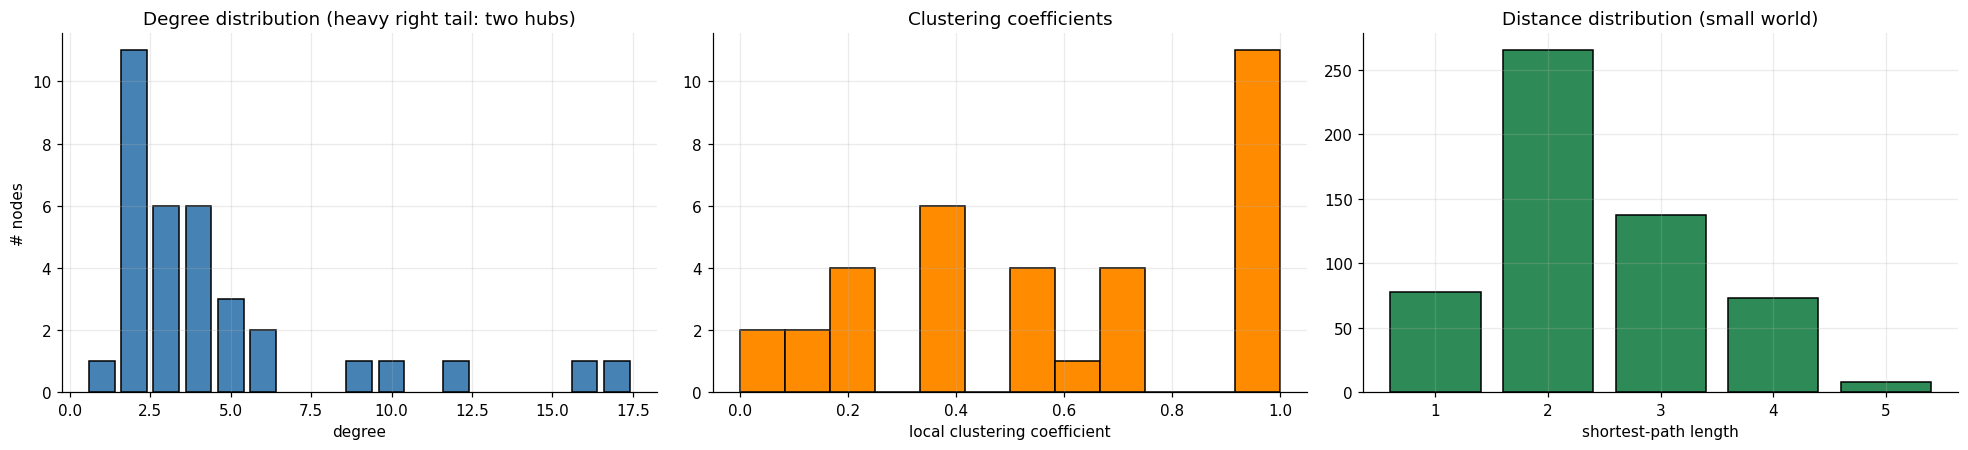

Only 4 nodes have degree >= 10: [0, 2, 32, 33]


In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(18, 4.2))
vals, cnts = np.unique(k, return_counts=True)
axs[0].bar(vals, cnts, color="steelblue", edgecolor="k"); axs[0].set_xlabel("degree"); axs[0].set_ylabel("# nodes")
axs[0].set_title("Degree distribution (heavy right tail: two hubs)")
cl = nx.clustering(G); axs[1].hist(list(cl.values()), bins=12, color="darkorange", edgecolor="k")
axs[1].set_xlabel("local clustering coefficient"); axs[1].set_title("Clustering coefficients")
sp = dict(nx.all_pairs_shortest_path_length(G)); d = [sp[u][v] for u in nodes for v in nodes if u < v]
v2, c2 = np.unique(d, return_counts=True); axs[2].bar(v2, c2, color="seagreen", edgecolor="k")
axs[2].set_xlabel("shortest-path length"); axs[2].set_title("Distance distribution (small world)")
plt.tight_layout(); plt.show()
print("Only", int((k >= 10).sum()), "nodes have degree >= 10:", [int(v) for v in np.where(k >= 10)[0]])

## Part 2 — The modularity matrix $B$

**Null model (configuration model).** Keep each node's degree $k_i$ but wire the $2m$ stubs (half-edges) at random. A stub of $i$ meets a stub of $j$ with probability $k_j/(2m)$, and $i$ has $k_i$ stubs, so

$$\mathbb E[A_{ij}] \;=\; \frac{k_i k_j}{2m}.$$

**Modularity matrix:**
$$B \;=\; A \;-\; \frac{k k^\top}{2m}, \qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.$$

* $B_{ij}>0$: $i,j$ are *more* connected than chance (an edge between low-degree nodes is surprising → large positive entry).
* $B_{ij}<0$: *less* connected than chance (e.g. two big hubs that are not linked).

Properties we verify numerically below (proofs are in the handout): (i) $B$ is real symmetric; (ii) $B\mathbf 1=\mathbf 0$ so $0$ is always an eigenvalue of the *global* $B$; (iii) the eigenvalues are real and an orthonormal eigenbasis exists.

In [ ]:
B = A - np.outer(k, k) / (2 * m)

print("shape:", B.shape)
print("symmetric (Prop. 1):               ", np.allclose(B, B.T))
print("max |row sum| = ||B·1||_inf (Prop. 2):", np.abs(B @ np.ones(n)).max())
print("sum of all entries of B:             ", round(B.sum(), 12))
print("trace(B) = -sum k_i^2/2m:            ", round(np.trace(B), 4), "(<0: diagonal is always negative)")

eigvals, eigvecs = np.linalg.eigh(B)                 # eigh: for symmetric matrices, ascending real eigenvalues
print("\nOrthonormal eigenvectors (Thm. 1): ||U^T U - I|| =", np.abs(eigvecs.T @ eigvecs - np.eye(n)).max())
print("smallest |eigenvalue| (should be ~0 because of B·1=0):", np.abs(eigvals).min())
print("largest eigenvalues  λ1..λ5:", np.round(eigvals[::-1][:5], 4))
print("number of positive eigenvalues:", int((eigvals > 1e-9).sum()), "| zero:", int((np.abs(eigvals) <= 1e-9).sum()),
      "| negative:", int((eigvals < -1e-9).sum()))
print("sum of eigenvalues = trace:", round(eigvals.sum(), 6))

shape: (34, 34)
symmetric (Prop. 1):                True
max |row sum| = ||B·1||_inf (Prop. 2): 8.881784197001252e-16
sum of all entries of B:              -0.0
trace(B) = -sum k_i^2/2m:             -7.7692 (<0: diagonal is always negative)

Orthonormal eigenvectors (Thm. 1): ||U^T U - I|| = 1.7763568394002505e-15
smallest |eigenvalue| (should be ~0 because of B·1=0): 6.276052305191211e-17
largest eigenvalues  λ1..λ5: [4.9771 3.0428 2.3202 1.4888 1.4594]
number of positive eigenvalues: 11 | zero: 11 | negative: 12
sum of eigenvalues = trace: -7.769231


In [ ]:
pairs = [(0, 1), (0, 2), (0, 33), (32, 33), (2, 32), (11, 0), (11, 33), (14, 15), (4, 10), (23, 29)]
rows = []
for i, j in pairs:
    rows.append({"pair (i,j)": f"({i},{j})", "A_ij": int(A[i, j]), "k_i": int(k[i]), "k_j": int(k[j]),
                 "expected k_i k_j / 2m": round(k[i] * k[j] / (2 * m), 3), "B_ij": round(B[i, j], 3),
                 "reading": "more than chance" if B[i, j] > 0 else "less than chance"})
print(pd.DataFrame(rows).to_string(index=False))
print("\nExample: nodes 0 and 33 are the two hubs with degrees", int(k[0]), "and", int(k[33]),
      f"→ the null model expects {k[0]*k[33]/(2*m):.3f} edges between them, but A_0,33 = {int(A[0,33])}, so B_0,33 = {B[0,33]:.3f} < 0.")
print("By contrast 4 and 10 are both low-degree and ARE linked: B_4,10 =", round(B[4, 10], 3), "(> 0, a 'surprising' edge).")

pair (i,j)  A_ij  k_i  k_j  expected k_i k_j / 2m   B_ij          reading
     (0,1)     1   16    9                  0.923  0.077 more than chance
     (0,2)     1   16   10                  1.026 -0.026 less than chance
    (0,33)     0   16   17                  1.744 -1.744 less than chance
   (32,33)     1   12   17                  1.308 -0.308 less than chance
    (2,32)     1   10   12                  0.769  0.231 more than chance
    (11,0)     1    1   16                  0.103  0.897 more than chance
   (11,33)     0    1   17                  0.109 -0.109 less than chance
   (14,15)     0    2    2                  0.026 -0.026 less than chance
    (4,10)     1    3    3                  0.058  0.942 more than chance
   (23,29)     1    5    4                  0.128  0.872 more than chance

Example: nodes 0 and 33 are the two hubs with degrees 16 and 17 → the null model expects 1.744 edges between them, but A_0,33 = 0, so B_0,33 = -1.744 < 0.
By contrast 4 and 10 are both 

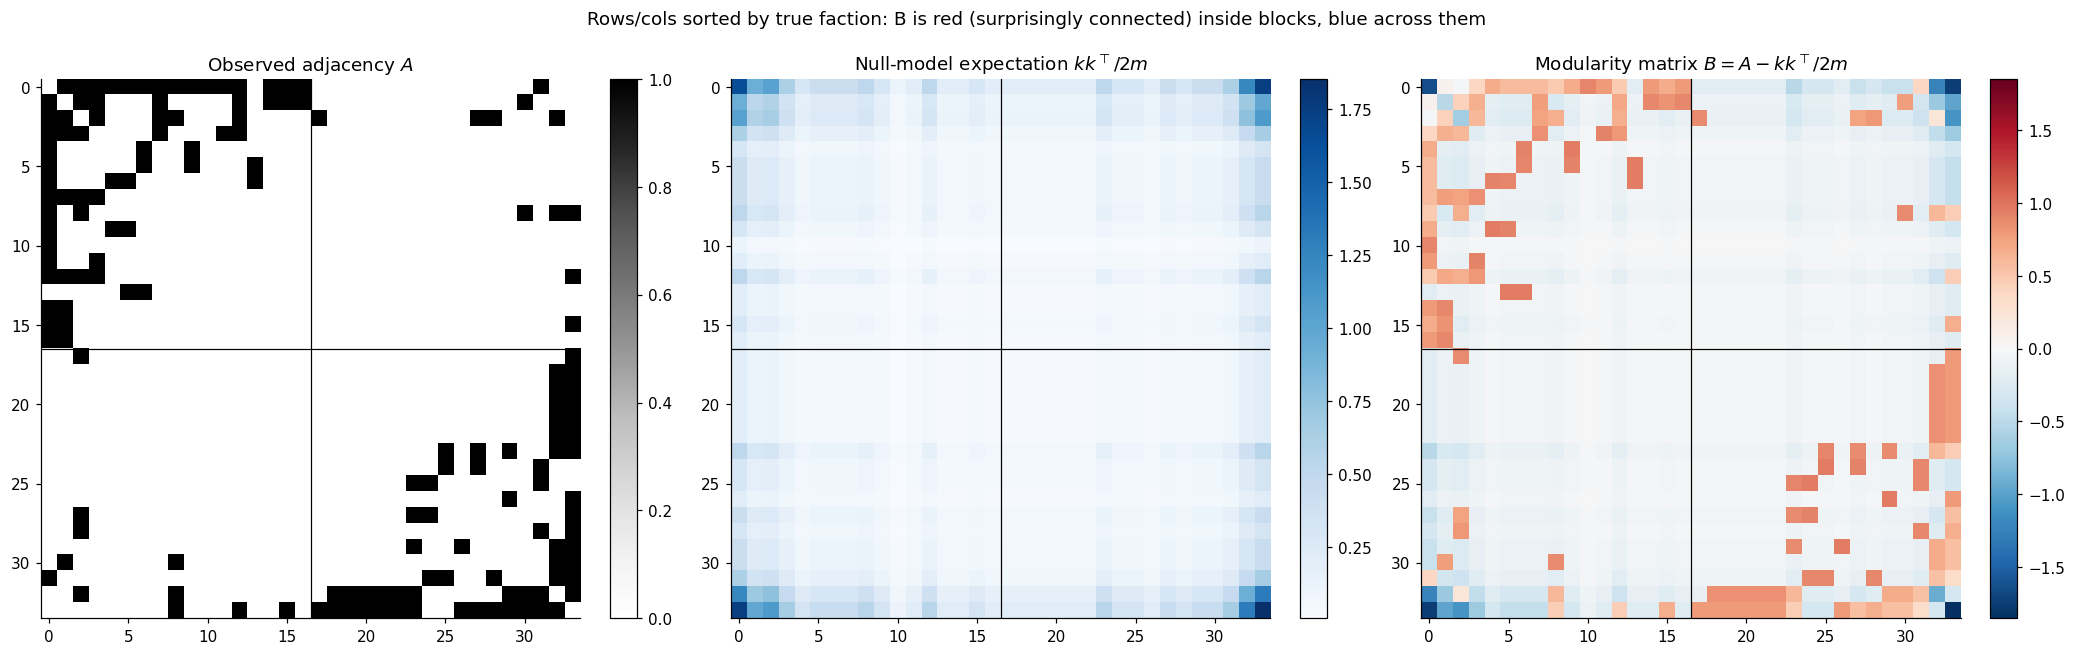

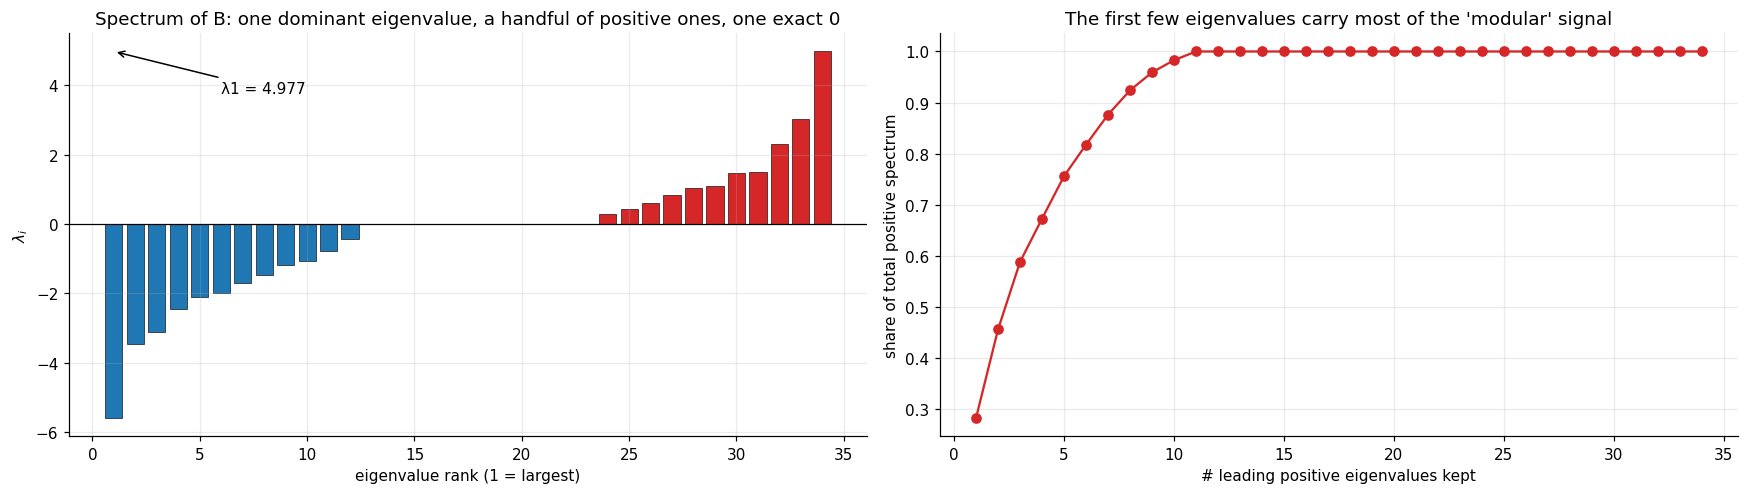

In [ ]:
E = np.outer(k, k) / (2 * m)
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6))
for ax, M, ttl, cm, sym in [(axs[0], A, "Observed adjacency $A$", "Greys", False),
                            (axs[1], E, r"Null-model expectation $kk^\top/2m$", "Blues", False),
                            (axs[2], B, r"Modularity matrix $B=A-kk^\top/2m$", "RdBu_r", True)]:
    Ms = M[np.ix_(order, order)]
    im = ax.imshow(Ms, cmap=cm, interpolation="nearest", **({"vmin": -abs(B).max(), "vmax": abs(B).max()} if sym else {}))
    ax.axhline(nb - .5, c="k", lw=.8); ax.axvline(nb - .5, c="k", lw=.8); ax.grid(False)
    ax.set_title(ttl); plt.colorbar(im, ax=ax, fraction=.046)
plt.suptitle("Rows/cols sorted by true faction: B is red (surprisingly connected) inside blocks, blue across them", y=1.02)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 2, figsize=(16, 4.6))
idx = np.arange(n, 0, -1)
axs[0].bar(idx, eigvals[::-1], color=["tab:red" if x > 1e-9 else ("grey" if abs(x) <= 1e-9 else "tab:blue") for x in eigvals[::-1]], edgecolor="k", lw=.4)
axs[0].axhline(0, c="k", lw=.8); axs[0].set_xlabel("eigenvalue rank (1 = largest)"); axs[0].set_ylabel("$\\lambda_i$")
axs[0].set_title("Spectrum of B: one dominant eigenvalue, a handful of positive ones, one exact 0")
axs[0].annotate(f"λ1 = {eigvals[-1]:.3f}", (1, eigvals[-1]), xytext=(6, eigvals[-1] - 1.2), arrowprops=dict(arrowstyle="->"))
axs[1].plot(np.arange(1, n + 1), np.cumsum(np.maximum(eigvals[::-1], 0)) / np.maximum(eigvals, 0).sum(), "o-", color="tab:red")
axs[1].set_xlabel("# leading positive eigenvalues kept"); axs[1].set_ylabel("share of total positive spectrum")
axs[1].set_title("The first few eigenvalues carry most of the 'modular' signal")
plt.tight_layout(); plt.show()

## Part 3 — The modularity score $Q$

For a division encoded by $s\in\{-1,+1\}^n$,
$$Q(s)=\frac{1}{4m}\,s^\top B\,s .$$
For *any* number of communities with labels $c_i$ the equivalent form is
$$Q=\frac1{2m}\sum_{i,j}B_{ij}\,\delta(c_i,c_j)=\sum_{c}\Big(\frac{e_c}{m}-\Big(\frac{K_c}{2m}\Big)^2\Big),$$
where $e_c$ is the number of edges inside community $c$ and $K_c=\sum_{i\in c}k_i$ (*observed fraction of edges inside* minus *fraction expected by the null model*). We implement both and cross-check them against NetworkX.

**Why not simply minimise the cut?** The cheapest cut isolates a low-degree vertex. We test this claim with data instead of just stating it.

In [ ]:
def Q_from_s(B, s, m):                      # two communities, s in {-1,+1}^n
    s = np.asarray(s, dtype=float); return float(s @ B @ s / (4 * m))

def Q_from_labels(B, labels, m):            # any number of communities
    l = np.asarray(labels); return float((B * (l[:, None] == l[None, :])).sum() / (2 * m))

def cut_size(A, s):                         # number of edges whose endpoints lie on different sides
    s = np.asarray(s, dtype=float); return int(round((A.sum() - s @ A @ s) / 4))

def refine_by_flips(B, s, m):               # greedy single-vertex moves (Kernighan–Lin style), used only as a benchmark
    s = np.array(s, dtype=float)
    while True:
        Bs = B @ s
        gain = (-4 * s * Bs + 4 * np.diag(B)) / (4 * m)     # exact ΔQ of flipping node i
        i = int(np.argmax(gain))
        if gain[i] <= 1e-12: return s
        s[i] *= -1

# --- cross-checks
comms_truth = [set(np.where(truth_labels == c)[0]) for c in (0, 1)]
q_nx = nx.community.modularity(G, comms_truth, weight=None)
print(f"Q(ground truth): 1/4m s'Bs = {Q_from_s(B, truth, m):.6f} | label form = {Q_from_labels(B, truth_labels, m):.6f} | networkx = {q_nx:.6f}")
assert np.isclose(Q_from_s(B, truth, m), q_nx) and np.isclose(Q_from_labels(B, truth_labels, m), q_nx)
print("Corollary 1: trivial partition s = 1 gives Q =", Q_from_s(B, np.ones(n), m))

Q(ground truth): 1/4m s'Bs = 0.358235 | label form = 0.358235 | networkx = 0.358235
Corollary 1: trivial partition s = 1 gives Q = 1.120898246015783e-17


In [ ]:
rng = np.random.default_rng(0)
examples = {
    "everyone in one group (s = 1)": np.ones(n),
    "ground truth (Mr. Hi vs Officer)": truth,
    "isolate node 11 (degree 1)": np.where(np.arange(n) == 11, 1, -1),
    "isolate node 33 (the hub)": np.where(np.arange(n) == 33, 1, -1),
    "isolate node 0 (Mr. Hi)": np.where(np.arange(n) == 0, 1, -1),
    "even vs odd node ids": np.where(np.arange(n) % 2 == 0, 1, -1),
    "first 17 ids vs last 17 ids": np.where(np.arange(n) < 17, 1, -1),
    "one random balanced split": rng.permutation(np.r_[np.ones(17), -np.ones(17)]),
}
rows = [{"partition": name, "cut size": cut_size(A, s), "sizes": f"{int((s==1).sum())}/{int((s==-1).sum())}",
         "Q": round(Q_from_s(B, s, m), 4)} for name, s in examples.items()]
print(pd.DataFrame(rows).to_string(index=False))

# every singleton cut
single = pd.DataFrame({"node": nodes, "degree": k.astype(int),
                       "cut": [cut_size(A, np.where(np.arange(n) == i, 1, -1)) for i in nodes],
                       "Q": [Q_from_s(B, np.where(np.arange(n) == i, 1, -1), m) for i in nodes]})
print("\nMinimum possible cut among singleton splits:", single.cut.min(), "→ achieved by nodes", list(single.node[single.cut == single.cut.min()]))
print("Ground-truth cut:", cut_size(A, truth), "edges. A min-cut method would prefer the 1-edge cut, yet its Q is only",
      round(float(single.Q[11]), 4), "vs", round(Q_from_s(B, truth, m), 4), "for the real split.")

                       partition  cut size sizes       Q
   everyone in one group (s = 1)         0  34/0  0.0000
ground truth (Mr. Hi vs Officer)        11 17/17  0.3582
      isolate node 11 (degree 1)         1  1/33 -0.0001
       isolate node 33 (the hub)        17  1/33 -0.0238
         isolate node 0 (Mr. Hi)        16  1/33 -0.0210
            even vs odd node ids        39 17/17 -0.0001
     first 17 ids vs last 17 ids        20 17/17  0.2433
       one random balanced split        38 17/17  0.0125

Minimum possible cut among singleton splits: 1 → achieved by nodes [11]
Ground-truth cut: 11 edges. A min-cut method would prefer the 1-edge cut, yet its Q is only -0.0001 vs 0.3582 for the real split.


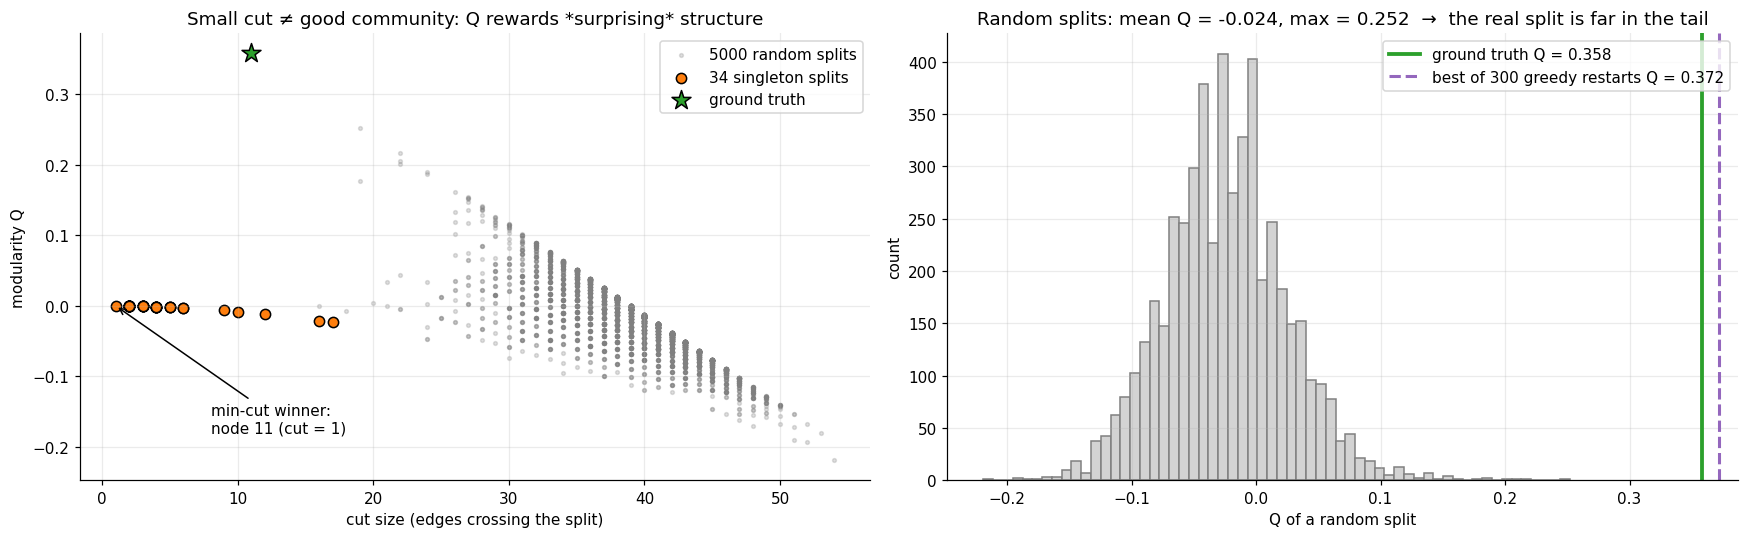

Random-split Q: mean -0.0242, sd 0.0489, 99.9th percentile 0.1871; z-score of ground truth ≈ 7.8 sd above random


In [ ]:
# 5000 random bisections: what does 'no structure' look like?
S = rng.choice([-1.0, 1.0], size=(5000, n))
Qr = np.einsum("ij,jk,ik->i", S, B, S) / (4 * m)
cutr = np.round((A.sum() - np.einsum("ij,jk,ik->i", S, A, S)) / 4).astype(int)

# best two-way Q found by 300 random restarts of greedy flipping (a strong benchmark; n = 34 is tiny)
best = max((Q_from_s(B, refine_by_flips(B, rng.choice([-1.0, 1.0], n), m), m) for _ in range(300)))

fig, axs = plt.subplots(1, 2, figsize=(16, 5))
axs[0].scatter(cutr, Qr, s=6, alpha=.25, c="grey", label="5000 random splits")
axs[0].scatter(single.cut, single.Q, c="tab:orange", s=45, edgecolor="k", label="34 singleton splits")
axs[0].scatter([cut_size(A, truth)], [Q_from_s(B, truth, m)], c="tab:green", s=170, marker="*", edgecolor="k", label="ground truth", zorder=5)
axs[0].annotate("min-cut winner:\nnode 11 (cut = 1)", (1, single.Q[11]), xytext=(8, -0.18), arrowprops=dict(arrowstyle="->"))
axs[0].set_xlabel("cut size (edges crossing the split)"); axs[0].set_ylabel("modularity Q")
axs[0].set_title("Small cut ≠ good community: Q rewards *surprising* structure"); axs[0].legend(loc="upper right")

axs[1].hist(Qr, bins=60, color="lightgrey", edgecolor="grey")
axs[1].axvline(Q_from_s(B, truth, m), c="tab:green", lw=2.5, label=f"ground truth Q = {Q_from_s(B, truth, m):.3f}")
axs[1].axvline(best, c="tab:purple", ls="--", lw=2, label=f"best of 300 greedy restarts Q = {best:.3f}")
axs[1].set_xlabel("Q of a random split"); axs[1].set_ylabel("count")
axs[1].set_title(f"Random splits: mean Q = {Qr.mean():.3f}, max = {Qr.max():.3f}  →  the real split is far in the tail")
axs[1].legend(); plt.tight_layout(); plt.show()
print(f"Random-split Q: mean {Qr.mean():.4f}, sd {Qr.std():.4f}, 99.9th percentile {np.quantile(Qr, .999):.4f}; "
      f"z-score of ground truth ≈ {(Q_from_s(B, truth, m) - Qr.mean())/Qr.std():.1f} sd above random")

## Part 4 — Spectral bipartition

Maximising $s^\top B s$ over $s\in\{\pm1\}^n$ needs $2^n$ evaluations ($2^{34}\approx1.7\times10^{10}$ here). **Relaxation:** allow real $s$ with $\|s\|_2=1$; by Rayleigh–Ritz the maximiser is the leading eigenvector $u_1$ (value $\lambda_1$). Then round: $s_i=+1$ if $(u_1)_i>0$ else $-1$.

Because $\|s\|^2=n$ for a $\pm1$ vector, we also get a rigorous **upper bound** for every bipartition: $Q\le n\lambda_1/(4m)$.

In [ ]:
def leading_eigenpair(M):
    # largest eigenvalue and unit eigenvector of a real symmetric matrix.
    # Eigenvectors are defined only up to sign; we fix the sign so that the entry of largest magnitude is positive.
    w, V = np.linalg.eigh(M)
    u = V[:, -1]; u = u * np.sign(u[np.argmax(np.abs(u))])
    return float(w[-1]), u

def sign_split(u, eps=1e-12):
    return np.where(u > eps, 1, -1)          # handout rule: +1 if (u1)_i > 0, else -1

lam1, u1 = leading_eigenpair(B)
s_spec = sign_split(u1)
agree = int((s_spec == truth).sum()); agree = max(agree, n - agree)        # overall sign of s is arbitrary
flip = 1 if (s_spec == truth).sum() >= n / 2 else -1
mis = [int(v) for v in np.where(flip * s_spec != truth)[0]]

print(f"λ1 = {lam1:.4f}   relaxed optimum of s'Bs/(4m) over unit vectors = λ1/(4m) = {lam1/(4*m):.5f}")
print(f"Q(sign-rounded u1) = {Q_from_s(B, s_spec, m):.4f}   | upper bound n·λ1/(4m) = {n*lam1/(4*m):.4f}   | best random-restart Q = {best:.4f}")
print(f"group sizes: {int((s_spec==1).sum())} / {int((s_spec==-1).sum())}   agreement with the real split: {agree}/{n} = {agree/n:.1%}")
print("misclassified node(s):", mis, "→ node", mis[0], "is", "a member of" , faction_name[mis[0]], "in reality")
print("nodes with |u1| < 0.05 (near the boundary, 'undecided'):", [int(v) for v in np.where(np.abs(u1) < 0.05)[0]])
s_ref = refine_by_flips(B, s_spec, m)
print(f"after greedy single-vertex refinement: Q = {Q_from_s(B, s_ref, m):.4f} (moved nodes: {[int(v) for v in np.where(s_ref != s_spec)[0]]})")

λ1 = 4.9771   relaxed optimum of s'Bs/(4m) over unit vectors = λ1/(4m) = 0.01595
Q(sign-rounded u1) = 0.3715   | upper bound n·λ1/(4m) = 0.5424   | best random-restart Q = 0.3718
group sizes: 16 / 18   agreement with the real split: 33/34 = 97.1%
misclassified node(s): [8] → node 8 is a member of Mr. Hi in reality
nodes with |u1| < 0.05 (near the boundary, 'undecided'): [9]
after greedy single-vertex refinement: Q = 0.3718 (moved nodes: [9])


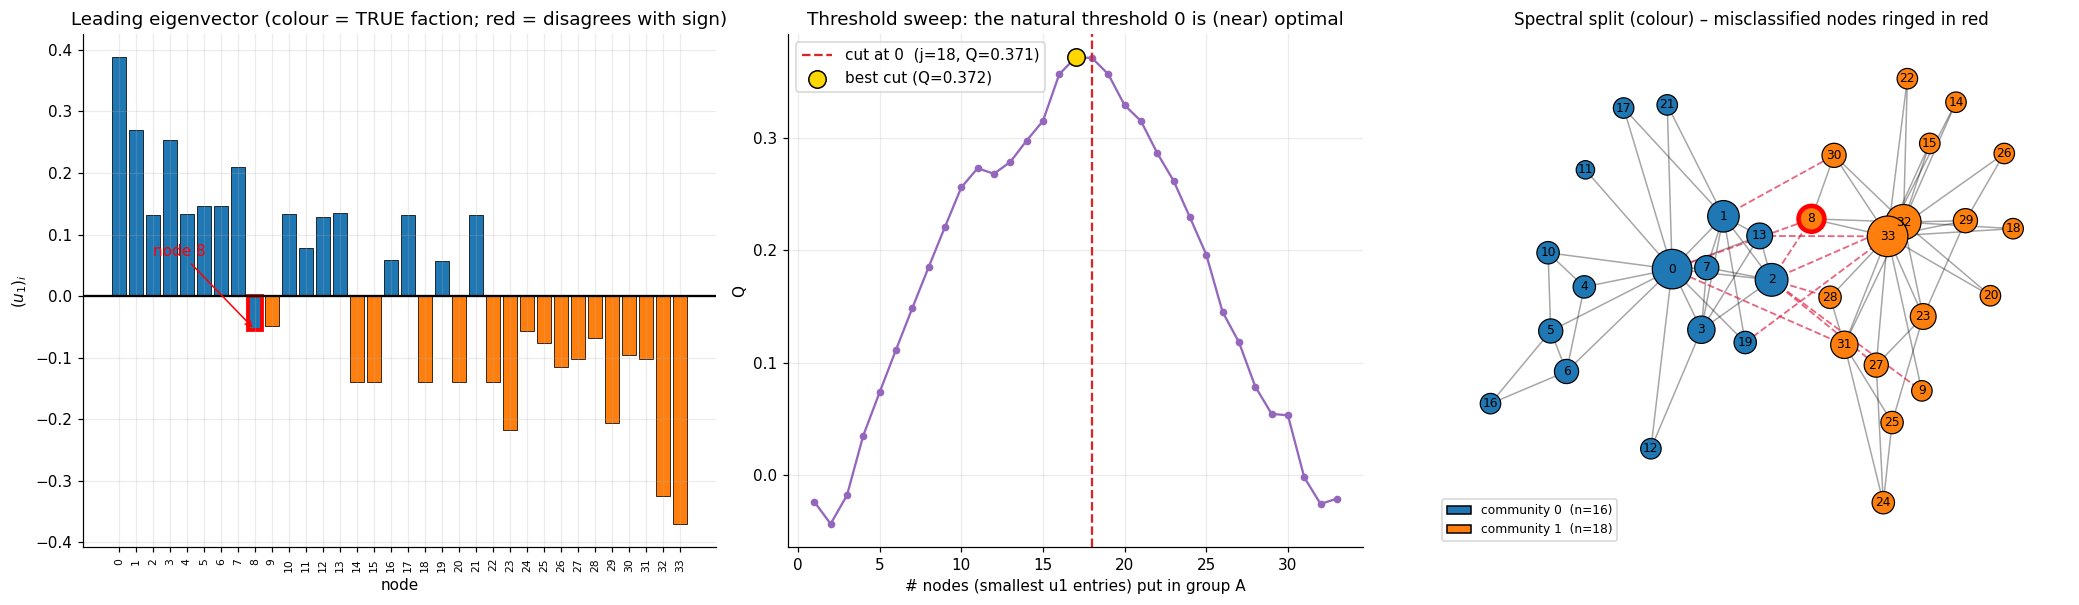

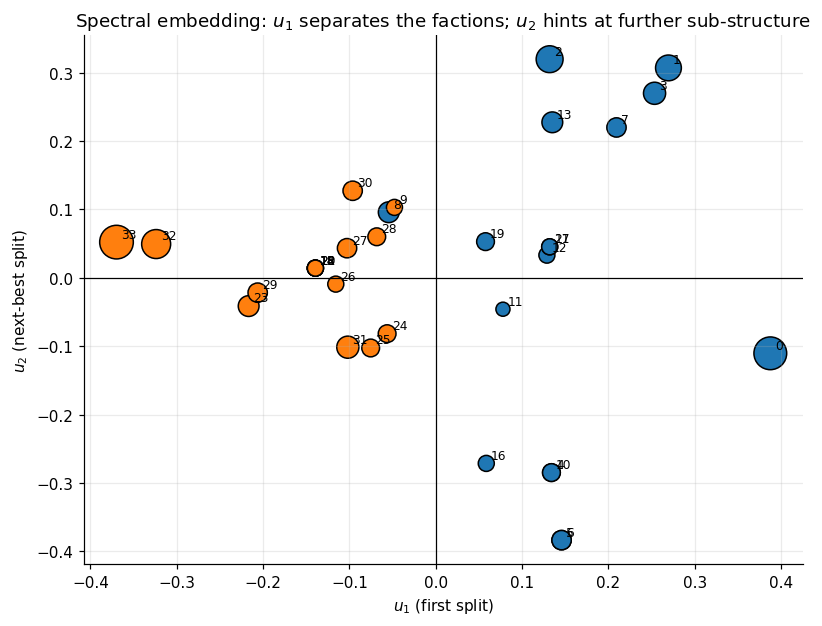

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(19, 5.6), gridspec_kw={"width_ratios": [1.1, 1, 1.1]})
cols = [PALETTE[c] for c in truth_labels]
axs[0].bar(nodes, flip * u1, color=cols, edgecolor=["red" if v in mis else "k" for v in nodes],
           linewidth=[2.5 if v in mis else .5 for v in nodes])
axs[0].axhline(0, c="k"); axs[0].set_xticks(nodes); axs[0].set_xticklabels(nodes, fontsize=7, rotation=90)
axs[0].set_xlabel("node"); axs[0].set_ylabel("$(u_1)_i$"); axs[0].set_title("Leading eigenvector (colour = TRUE faction; red = disagrees with sign)")
for v in mis: axs[0].annotate(f"node {v}", (v, flip * u1[v]), xytext=(v - 6, flip * u1[v] + .12), arrowprops=dict(arrowstyle="->", color="red"), color="red")

# threshold sweep: instead of cutting at 0, cut the sorted eigenvector at every position
srt = np.argsort(u1); Qsweep = []
for j in range(1, n):
    s = -np.ones(n); s[srt[j:]] = 1; Qsweep.append(Q_from_s(B, s, m))
j0 = int((u1 <= 1e-12).sum())
axs[1].plot(range(1, n), Qsweep, "o-", ms=4, color="tab:purple")
axs[1].axvline(j0, c="tab:red", ls="--", label=f"cut at 0  (j={j0}, Q={Q_from_s(B, s_spec, m):.3f})")
axs[1].scatter([1 + int(np.argmax(Qsweep))], [max(Qsweep)], c="gold", s=130, edgecolor="k", zorder=5, label=f"best cut (Q={max(Qsweep):.3f})")
axs[1].set_xlabel("# nodes (smallest u1 entries) put in group A"); axs[1].set_ylabel("Q"); axs[1].legend()
axs[1].set_title("Threshold sweep: the natural threshold 0 is (near) optimal")

draw_partition(G, pos, np.where(flip * s_spec == 1, 0, 1), axs[2], "Spectral split (colour) – misclassified nodes ringed in red",
               highlight=set(mis)); community_legend(np.where(flip * s_spec == 1, 0, 1), axs[2])
plt.tight_layout(); plt.show()

# 2-D spectral embedding with first two eigenvectors
w, V = np.linalg.eigh(B); u2 = V[:, -2]
fig, ax = plt.subplots(figsize=(7.5, 5.8))
ax.scatter(u1, u2, c=cols, s=60 + 25 * k, edgecolor="k")
for v in nodes: ax.annotate(str(v), (u1[v], u2[v]), xytext=(3, 3), textcoords="offset points", fontsize=8)
ax.axvline(0, c="k", lw=.8); ax.axhline(0, c="k", lw=.8); ax.set_xlabel("$u_1$ (first split)"); ax.set_ylabel("$u_2$ (next-best split)")
ax.set_title("Spectral embedding: $u_1$ separates the factions; $u_2$ hints at further sub-structure")
plt.tight_layout(); plt.show()

## Part 5 — Recursive spectral bisection

### Pseudocode (as in the handout)
```
labels ← all nodes in community 0;  queue ← [0]
while queue not empty:
    c ← queue.pop();  C ← {i : labels[i] = c}
    B_C ← B[C, C]                              # restriction of the GLOBAL B to C
    (λ1, u1) ← leading eigenpair of B_C
    if λ1 ≤ 0:                       mark C final; continue        # Theorem 3
    s ← sign(u1)
    if s is constant:                mark C final; continue        # cannot split by sign
    ΔQ ← actual modularity change of the split
    if ΔQ ≤ 0:                       mark C final; continue        # safety net
    C+ keeps id c, C− gets a new id;  queue ← queue + [c, new id]
    record a snapshot (labels, Q, λ1, ΔQ)  ← one "iteration"
```
### Two variants (we run both and compare)
| variant | matrix used for community $C$ | comment |
|---|---|---|
| **`handout`** (the assignment's specification) | $B^{(C)}=B[C,C]$ | exactly what the handout states |
| **`corrected`** (Newman 2006, Eq. 6) | $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$ | subtracts each row sum on the diagonal so that $\mathbf 1$ is again an eigenvector with eigenvalue 0 and $\Delta Q=\frac1{4m}s^\top B^{(g)}s$ is *exact* |

Part 7 explains numerically why the correction exists. The *main* analysis (Parts 6, 8–10) follows the handout; the corrected variant is carried along for comparison.

In [ ]:
def recursive_spectral(A, variant="handout", tol=1e-9, require_gain=True):
    # Recursive spectral modularity bisection.
    # Returns {'history': one snapshot per successful split (iteration 0 = no split),
    #          'log': every decision taken (split / stop), 'labels': final labels, 'B': B, 'm': m}
    assert variant in ("handout", "corrected")
    n = A.shape[0]; kk = A.sum(1); mm = kk.sum() / 2
    Bg = A - np.outer(kk, kk) / (2 * mm)
    labels = np.zeros(n, dtype=int); next_id = 1; queue = [0]
    Q0 = Q_from_labels(Bg, labels, mm)
    history = [dict(iteration=0, labels=labels.copy(), Q=Q0, event="start: whole graph = 1 community", parent=None,
                    lam=np.nan, dQ=0.0, dQ_handout=np.nan, dQ_corrected=np.nan, sizes=(n,))]
    log, it = [], 0
    while queue:
        c = queue.pop(0); idx = np.where(labels == c)[0]
        Bc = Bg[np.ix_(idx, idx)]
        Bd = Bc - np.diag(Bc.sum(axis=1)) if variant == "corrected" else Bc
        lam, u = leading_eigenpair(Bd)
        rec = dict(community=c, size=len(idx), lam1=lam)
        if lam <= tol:
            log.append({**rec, "decision": "STOP: λ1 ≤ 0 (no split can raise Q)", "dQ": np.nan}); continue
        s = sign_split(u)
        if abs(int(s.sum())) == len(s):
            log.append({**rec, "decision": "STOP: λ1 > 0 but sign vector is constant (no non-trivial split)", "dQ": np.nan}); continue
        new = labels.copy(); new[idx[s == -1]] = next_id
        dQ = Q_from_labels(Bg, new, mm) - Q_from_labels(Bg, labels, mm)
        if require_gain and dQ <= tol:
            log.append({**rec, "decision": "STOP: sign split would not raise Q", "dQ": dQ}); continue
        it += 1
        f_handout = float(s @ Bc @ s / (4 * mm)); f_corr = float((s @ Bc @ s - Bc.sum()) / (4 * mm))
        labels = new
        history.append(dict(iteration=it, labels=labels.copy(), Q=Q_from_labels(Bg, labels, mm), parent=c, lam=lam, dQ=dQ,
                            dQ_handout=f_handout, dQ_corrected=f_corr, sizes=(int((s == 1).sum()), int((s == -1).sum())),
                            event=f"split community {c} (n={len(idx)}) → {c} (n={int((s==1).sum())}) + {next_id} (n={int((s==-1).sum())})"))
        log.append({**rec, "decision": f"SPLIT → {c} (n={int((s==1).sum())}) + {next_id} (n={int((s==-1).sum())})", "dQ": dQ})
        queue += [c, next_id]; next_id += 1
    return dict(history=history, log=log, labels=labels, B=Bg, m=mm)

RES = {"handout": recursive_spectral(A, "handout"), "corrected": recursive_spectral(A, "corrected")}
for name, r in RES.items():
    print(f"\n================ variant = {name} ================")
    lg = pd.DataFrame(r["log"]); lg.index = lg.index + 1; lg.index.name = "step"
    lg["lam1"] = lg["lam1"].round(4); lg["dQ"] = lg["dQ"].round(4)
    print(lg[["community", "size", "lam1", "decision", "dQ"]].to_string())
    print(f"→ {len(np.unique(r['labels']))} communities, final Q = {Q_from_labels(r['B'], r['labels'], r['m']):.4f}; "
          f"networkx check: {nx.community.modularity(G, [set(np.where(r['labels']==c)[0]) for c in np.unique(r['labels'])], weight=None):.4f}")


================ variant = handout ================
      community  size    lam1                                                         decision      dQ
step                                                                                                  
1             0    34  4.9771                                      SPLIT → 0 (n=16) + 1 (n=18)  0.3715
2             0    16  2.9441                                       SPLIT → 0 (n=10) + 2 (n=6)  0.0183
3             1    18  2.5041                                       SPLIT → 1 (n=13) + 3 (n=5)  0.0183
4             0    10  2.5712  STOP: λ1 > 0 but sign vector is constant (no non-trivial split)     NaN
5             2     6  2.1480                                        SPLIT → 2 (n=5) + 4 (n=1)  0.0013
6             1    13  2.3563  STOP: λ1 > 0 but sign vector is constant (no non-trivial split)     NaN
7             3     5  1.8759  STOP: λ1 > 0 but sign vector is constant (no non-trivial split)     NaN
8             2     

In [ ]:
def describe(history):
    print(f"{'iter':>4} | {'event':<62} | {'λ1':>7} | {'ΔQ':>8} | {'Q':>7}")
    for h in history:
        lam = "—" if np.isnan(h["lam"]) else f"{h['lam']:.3f}"
        print(f"{h['iteration']:>4} | {h['event']:<62} | {lam:>7} | {h['dQ']:>+8.4f} | {h['Q']:>7.4f}")

for name, r in RES.items():
    print(f"\n[{name}]"); describe(r["history"])

print("\nFinal communities (handout variant):")
fl = RES["handout"]["labels"]
for c in np.unique(fl):
    mem = [int(v) for v in np.where(fl == c)[0]]
    print(f"  community {c} (n={len(mem):2d}): {mem}   true factions inside: "
          f"{dict(pd.Series(faction_name[mem]).value_counts())}")
print("\nFinal communities (corrected variant):")
fl2 = RES["corrected"]["labels"]
for c in np.unique(fl2):
    mem = [int(v) for v in np.where(fl2 == c)[0]]
    print(f"  community {c} (n={len(mem):2d}): {mem}   true factions inside: "
          f"{dict(pd.Series(faction_name[mem]).value_counts())}")


[handout]
iter | event                                                          |      λ1 |       ΔQ |       Q
   0 | start: whole graph = 1 community                               |       — |  +0.0000 | -0.0000
   1 | split community 0 (n=34) → 0 (n=16) + 1 (n=18)                 |   4.977 |  +0.3715 |  0.3715
   2 | split community 0 (n=16) → 0 (n=10) + 2 (n=6)                  |   2.944 |  +0.0183 |  0.3898
   3 | split community 1 (n=18) → 1 (n=13) + 3 (n=5)                  |   2.504 |  +0.0183 |  0.4081
   4 | split community 2 (n=6) → 2 (n=5) + 4 (n=1)                    |   2.148 |  +0.0013 |  0.4094

[corrected]
iter | event                                                          |      λ1 |       ΔQ |       Q
   0 | start: whole graph = 1 community                               |       — |  +0.0000 | -0.0000
   1 | split community 0 (n=34) → 0 (n=16) + 1 (n=18)                 |   4.977 |  +0.3715 |  0.3715
   2 | split community 0 (n=16) → 0 (n=9) + 2 (n=7)                

## Part 6 — Visualisation after every split

Layout is **fixed** (`pos`), nodes are labelled by id, and each community keeps its colour for as long as it exists: when a community splits, the "+" part keeps the parent's colour and the "−" part receives a new colour. Node size ∝ degree. **Red dashed edges** cross community boundaries, so the cut is visible at a glance.

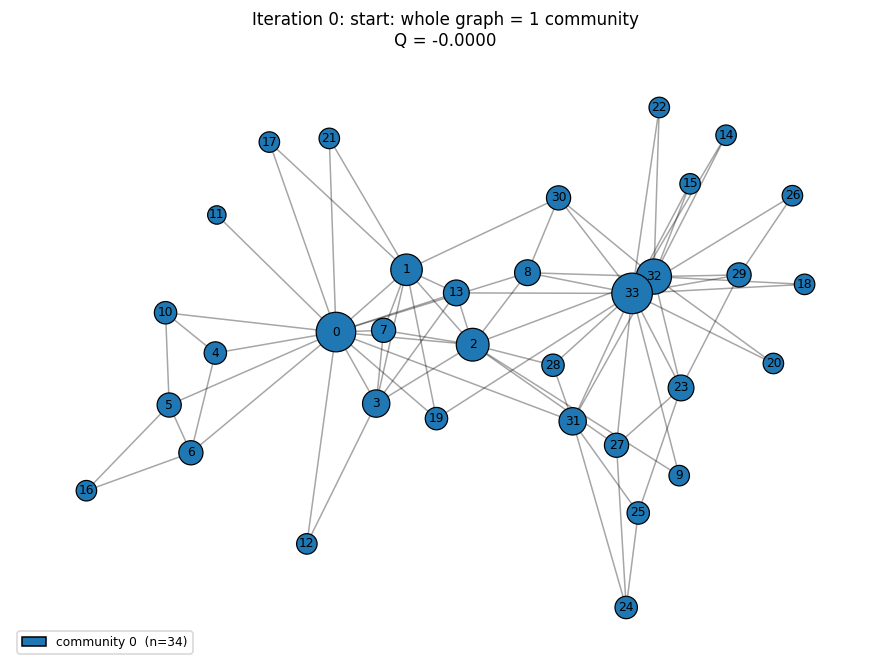

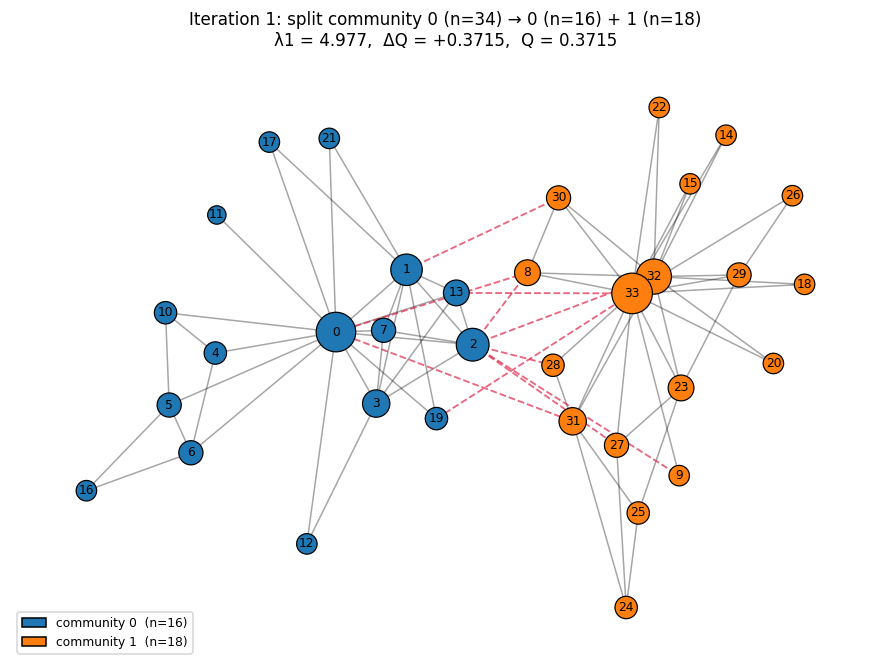

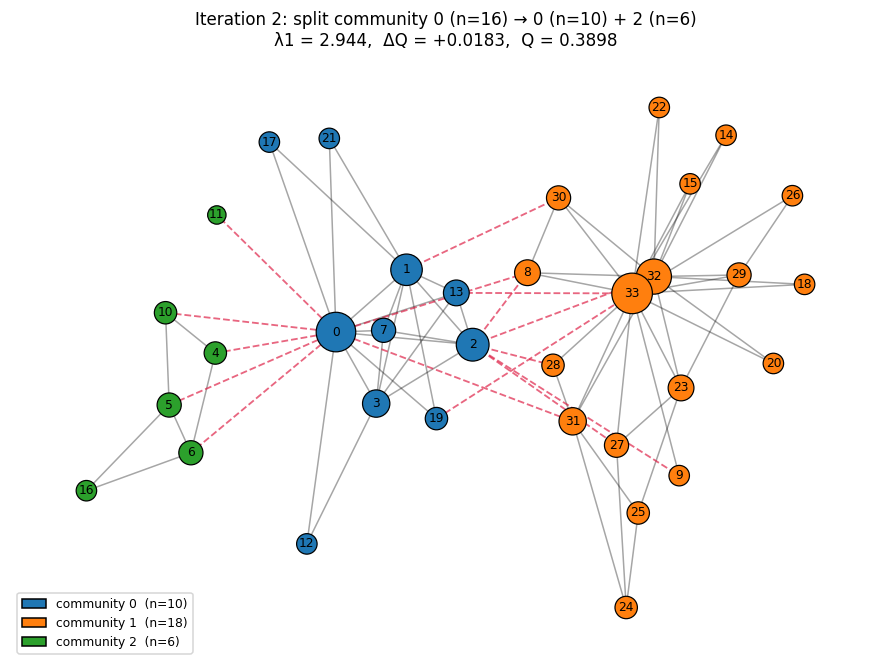

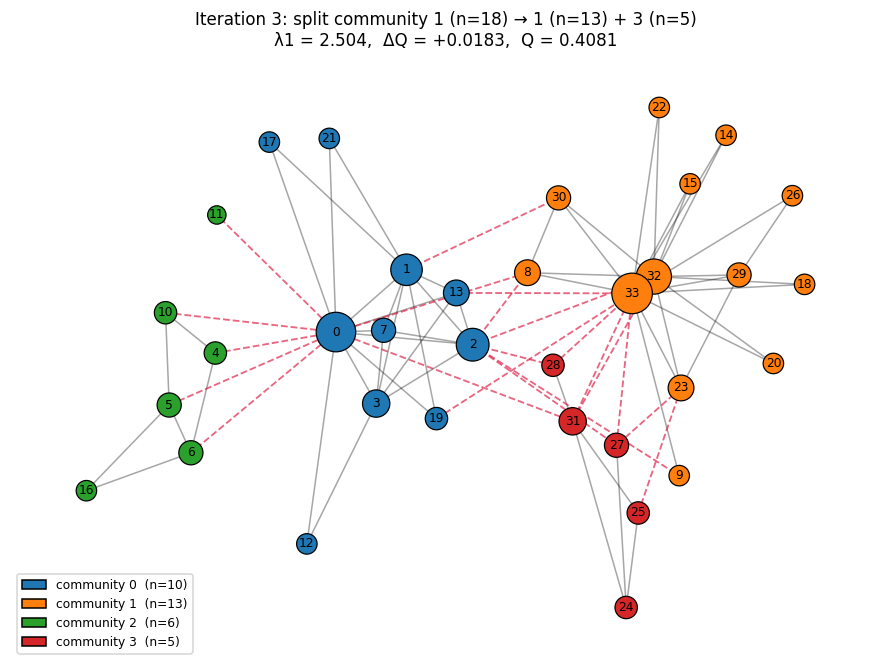

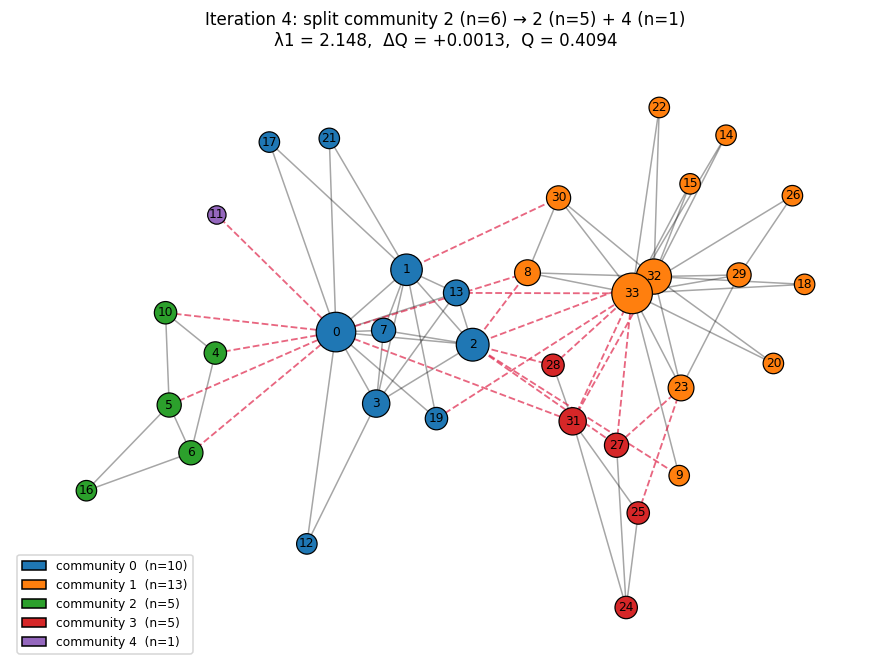

In [ ]:
HIST = RES["handout"]["history"]
for h in HIST:
    fig, ax = plt.subplots(figsize=(8.2, 6.2))
    ttl = (f"Iteration {h['iteration']}: {h['event']}\n" + (f"λ1 = {h['lam']:.3f},  ΔQ = {h['dQ']:+.4f},  " if h['iteration'] else "") + f"Q = {h['Q']:.4f}")
    draw_partition(G, pos, h["labels"], ax, ttl); community_legend(h["labels"], ax)
    plt.tight_layout(); plt.show()

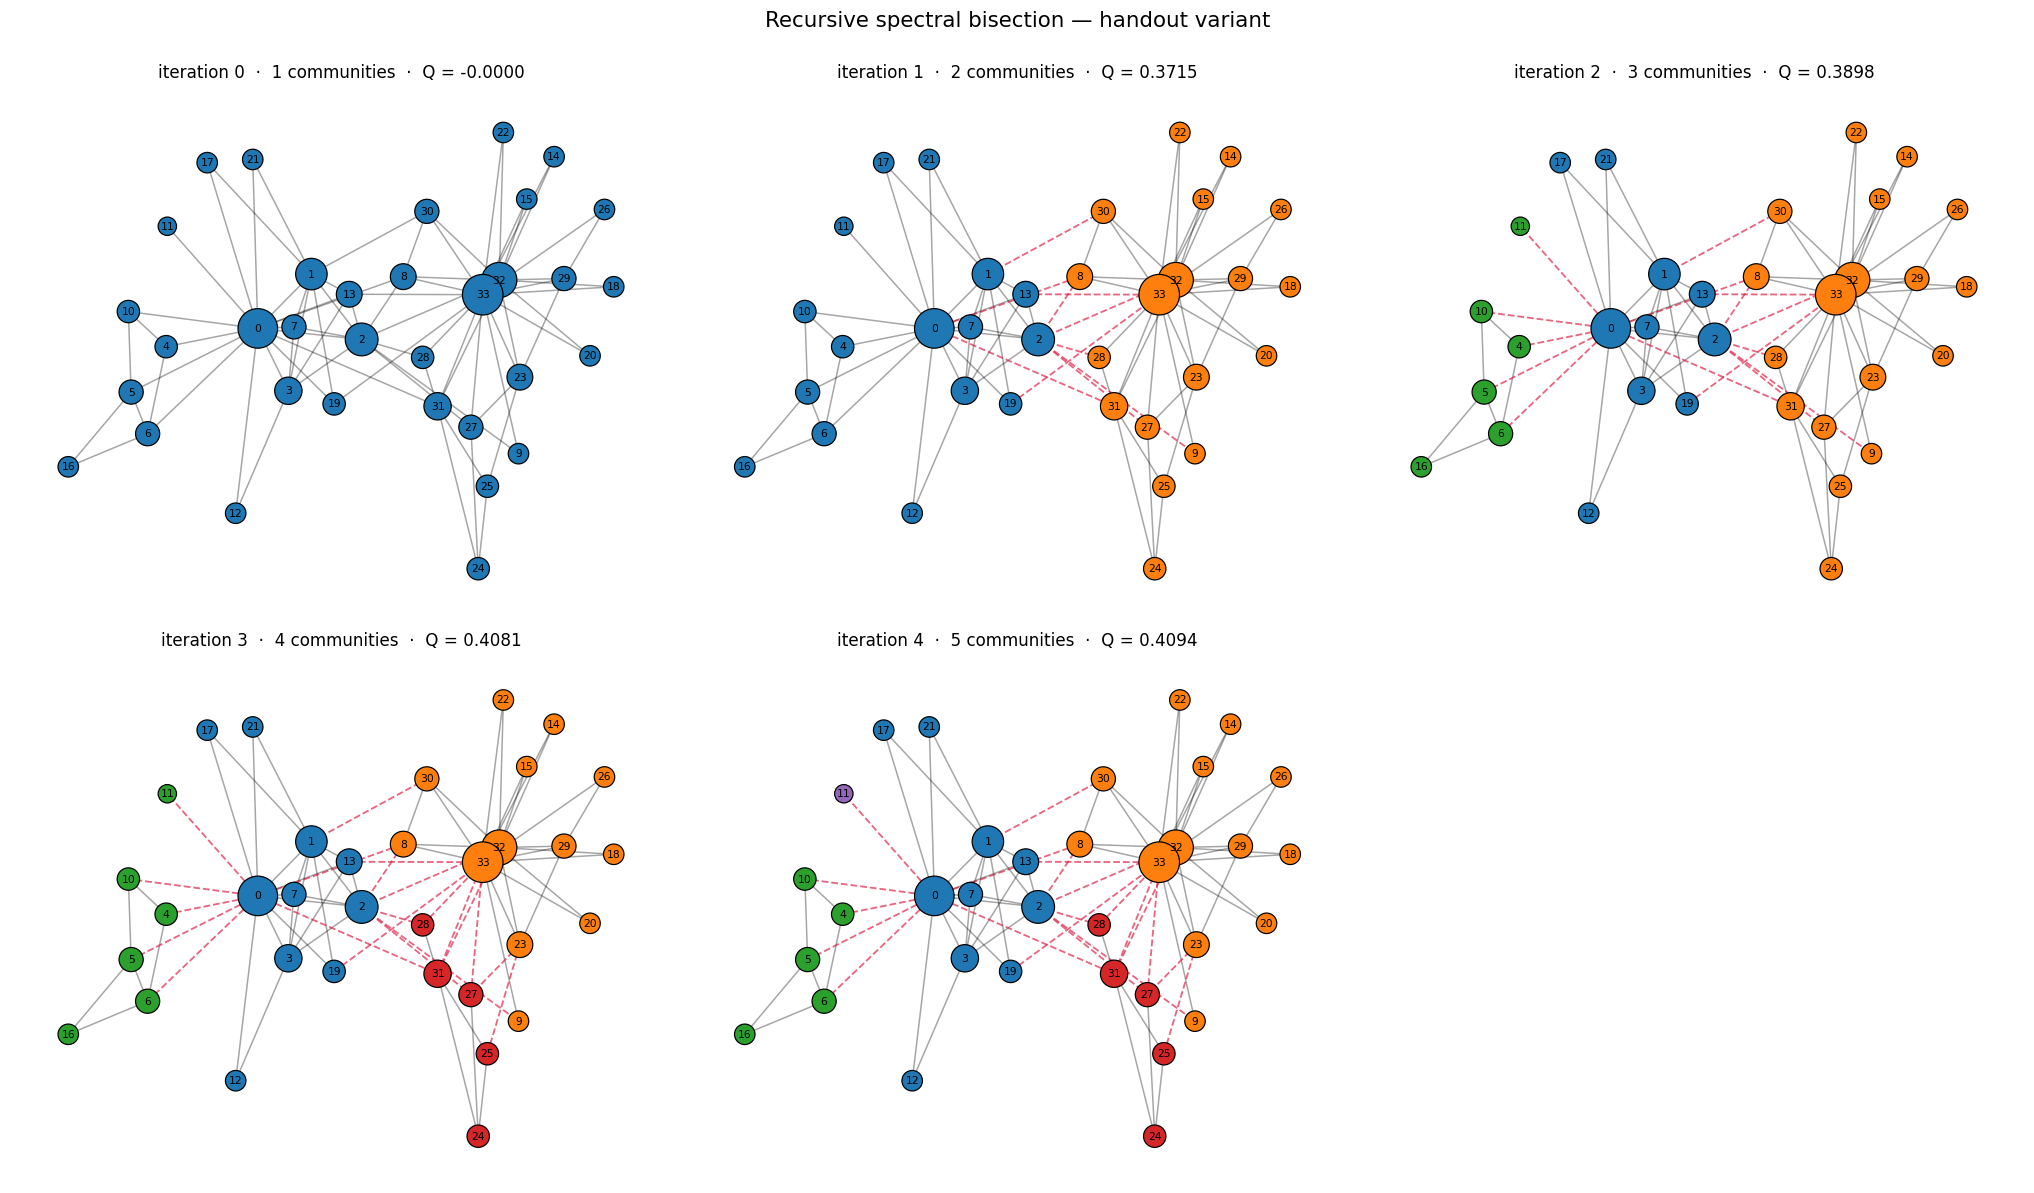

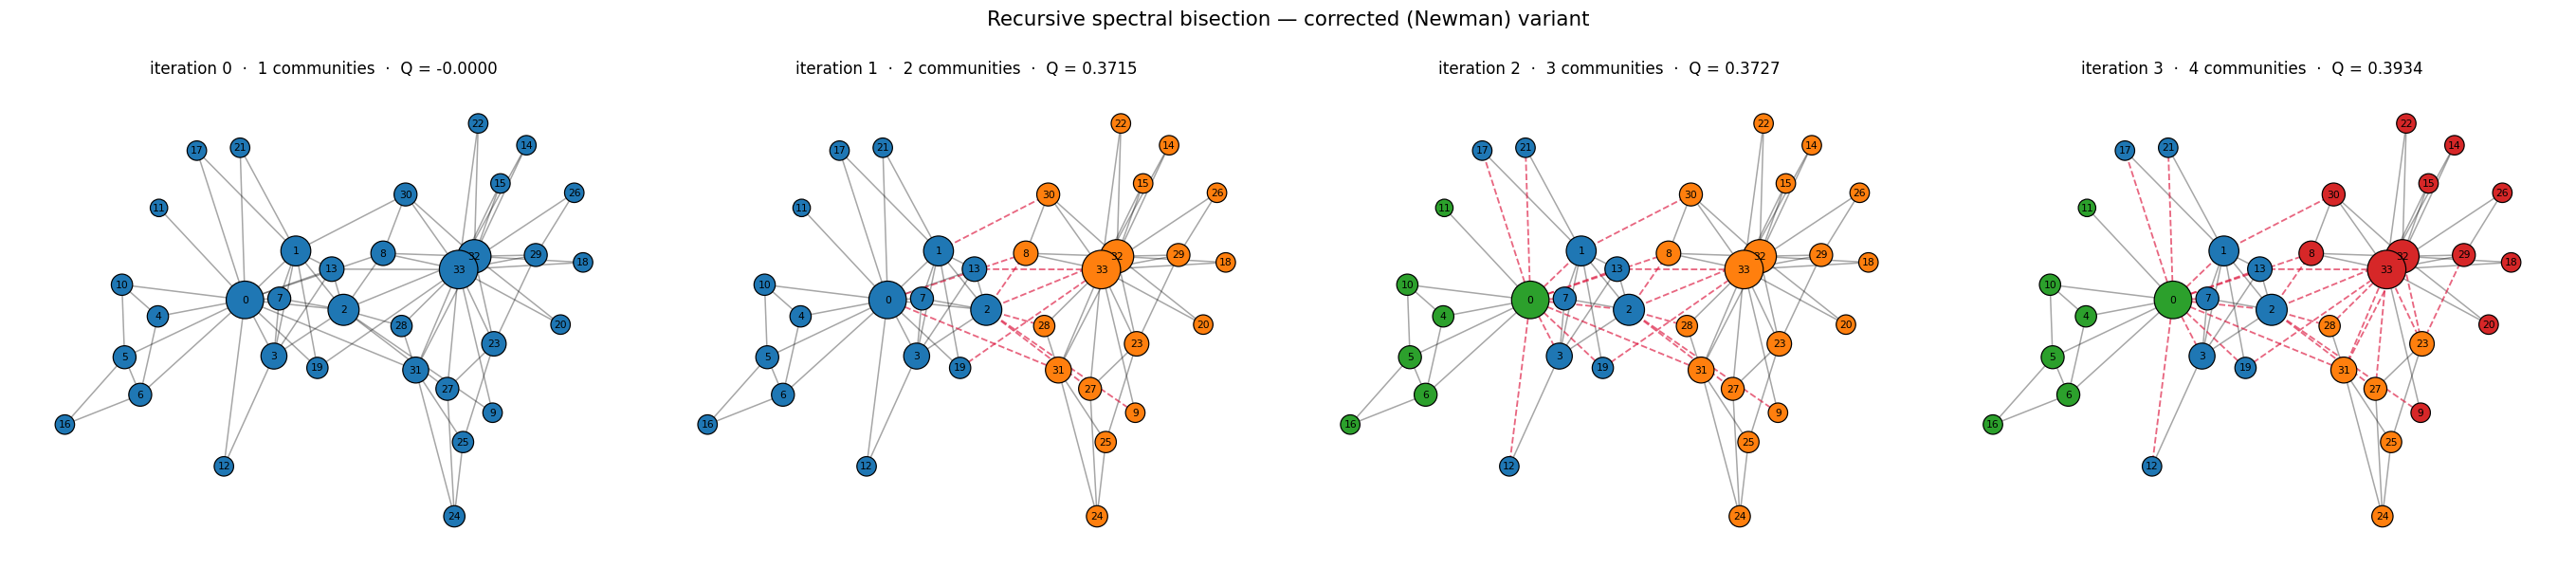

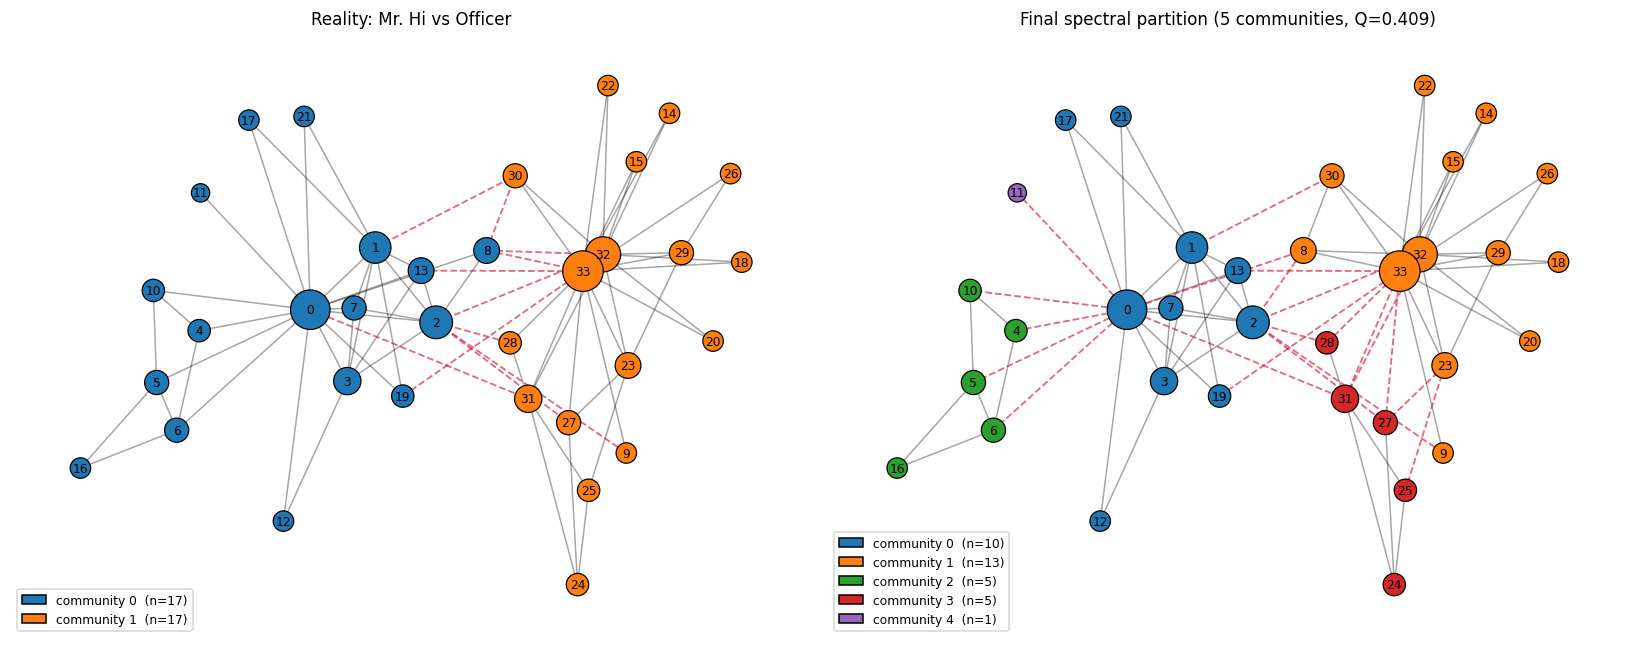

In [ ]:
def snapshot_grid(history, title, ncols=3):
    nrows = int(np.ceil(len(history) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(6.2 * ncols, 5.4 * nrows)); axs = np.atleast_1d(axs).ravel()
    for ax, h in zip(axs, history):
        draw_partition(G, pos, h["labels"], ax, f"iteration {h['iteration']}  ·  {len(np.unique(h['labels']))} communities  ·  Q = {h['Q']:.4f}", font_size=7)
    for ax in axs[len(history):]: ax.set_axis_off()
    fig.suptitle(title, fontsize=14, y=1.0); plt.tight_layout(); plt.show()

snapshot_grid(RES["handout"]["history"], "Recursive spectral bisection — handout variant")
snapshot_grid(RES["corrected"]["history"], "Recursive spectral bisection — corrected (Newman) variant", ncols=4)

# Overlay the real split on the first iteration: which nodes are 'wrong'?
fig, axs = plt.subplots(1, 2, figsize=(15, 6))
draw_partition(G, pos, truth_labels, axs[0], "Reality: Mr. Hi vs Officer"); community_legend(truth_labels, axs[0])
last = RES["handout"]["history"][-1]["labels"]
draw_partition(G, pos, last, axs[1], f"Final spectral partition ({len(np.unique(last))} communities, Q={RES['handout']['history'][-1]['Q']:.3f})")
community_legend(last, axs[1]); plt.tight_layout(); plt.show()

## Part 7 — A closer look at the $\Delta Q$ identity and the stopping rule

The handout states that splitting a community $C$ by $s$ changes modularity by $\Delta Q=\frac1{4m}s^\top B^{(C)}s$. Let us derive what is *exactly* true. With $Q=\frac1{2m}\sum_{ij}B_{ij}\delta(c_i,c_j)$, splitting $C$ into $C_+,C_-$ removes the cross terms:
$$\Delta Q=-\frac1{m}\sum_{i\in C_+,\,j\in C_-}B_{ij}=\frac1{4m}\Big(s^\top B^{(C)}s-\mathbf 1^\top B^{(C)}\mathbf 1\Big)=\frac1{4m}\,s^\top B^{(g)}s,$$
because $s^\top\mathrm{diag}(\text{row sums})\,s=\mathbf 1^\top B^{(C)}\mathbf 1$. So the handout formula is exact **when $\mathbf 1^\top B^{(C)}\mathbf 1=0$**, which holds for the first split ($C=V$, since $B\mathbf 1=0$) but **not in general** for a sub-community. The code below checks all three quantities on every split we performed.

In [ ]:
rows = []
for name, r in RES.items():
    for h in r["history"][1:]:
        rows.append({"variant": name, "iteration": h["iteration"], "parent size": sum(h["sizes"]),
                     "true ΔQ (recomputed)": round(h["dQ"], 5),
                     "handout formula s'B_C s/4m": round(h["dQ_handout"], 5),
                     "corrected formula (s'B_C s − 1'B_C 1)/4m": round(h["dQ_corrected"], 5)})
chk = pd.DataFrame(rows); print(chk.to_string(index=False))
assert np.allclose(chk["true ΔQ (recomputed)"], chk["corrected formula (s'B_C s − 1'B_C 1)/4m"], atol=1e-5)
print("\n✔ The corrected formula reproduces the true ΔQ on every split.")
print("✘ The handout formula equals it only for iteration 1 (where C = V and 1'B1 = 0); afterwards it OVER-states the gain.")

  variant  iteration  parent size  true ΔQ (recomputed)  handout formula s'B_C s/4m  corrected formula (s'B_C s − 1'B_C 1)/4m
  handout          1           34               0.37147                     0.37147                                   0.37147
  handout          2           16               0.01833                     0.11119                                   0.01833
  handout          3           18               0.01833                     0.11119                                   0.01833
  handout          4            6               0.00131                     0.03384                                   0.00131
corrected          1           34               0.37147                     0.37147                                   0.37147
corrected          2           16               0.00123                     0.09410                                   0.00123
corrected          3           18               0.02071                     0.11358                                   

In [ ]:
# Why does it matter?  1'B_C 1 > 0 for a tight community, so B_C has a large positive eigenvalue even when no good split exists.
print("Leading eigenvalue of the two matrices for each final community of the handout run:\n")
rows = []
for c in np.unique(RES["handout"]["labels"]):
    idx = np.where(RES["handout"]["labels"] == c)[0]
    Bc = B[np.ix_(idx, idx)]; Bg_ = Bc - np.diag(Bc.sum(1))
    lam_h, u_h = leading_eigenpair(Bc); lam_c, _ = leading_eigenpair(Bg_)
    rows.append({"community": int(c), "size": len(idx), "1'B_C 1": round(Bc.sum(), 3), "λ1(B_C) handout": round(lam_h, 4),
                 "λ1(B^(g)) corrected": round(lam_c, 4), "sign(u1) constant?": bool(abs(sign_split(u_h).sum()) == len(idx))})
print(pd.DataFrame(rows).to_string(index=False))
print("\nA positive λ1(B_C) together with a *constant-sign* u1 means 'the handout test says split, but the sign rule cannot split':"
      "\nthis is why the implementation needs the 'constant sign vector' guard, and why the corrected matrix (whose λ1 is ≈ 0 for such groups) is the principled test.")

Leading eigenvalue of the two matrices for each final community of the handout run:

 community  size  1'B_C 1  λ1(B_C) handout  λ1(B^(g)) corrected  sign(u1) constant?
         0    10   21.686           2.5712                 -0.0                True
         1    13   24.147           2.3563                  0.0                True
         2     5   10.359           2.1470                 -0.0                True
         3     5    7.686           1.8759                  0.0                True
         4     1   -0.006          -0.0064                  0.0                True

A positive λ1(B_C) together with a *constant-sign* u1 means 'the handout test says split, but the sign rule cannot split':
this is why the implementation needs the 'constant sign vector' guard, and why the corrected matrix (whose λ1 is ≈ 0 for such groups) is the principled test.


## Part 8 — Node metrics after every split

The four metrics (NetworkX built-ins):

| metric | NetworkX call | meaning |
|---|---|---|
| degree centrality $C_D(i)=k_i/(n-1)$ | `nx.degree_centrality` | share of the other nodes that $i$ touches directly (hubs) |
| betweenness $C_B(i)=\sum_{s\ne i\ne t}\sigma_{st}(i)/\sigma_{st}$ | `nx.betweenness_centrality` | how often $i$ lies on shortest paths (brokers) |
| closeness $C_C(i)=(n-1)/\sum_j d(i,j)$ | `nx.closeness_centrality` | how quickly $i$ reaches everyone |
| clustering $C(i)=2T(i)/(k_i(k_i-1))$ | `nx.clustering` | how many of $i$'s neighbours know each other |

**Design decision — what does "after each split" mean?** Computed on the *whole* graph the four metrics never change, so there would be nothing to plot. We therefore evaluate every metric on the **subgraph induced by the node's current community** (`G.subgraph(community)`), i.e. *"how important is this node inside the community it belongs to at this iteration?"*. Iteration 0 (everyone in one community) is exactly the classical whole-graph metric, so it doubles as the reference value. Conventions: a community of one node gets 0 for all metrics; closeness on a disconnected community uses NetworkX's default Wasserman–Faust scaling.

In [ ]:
METRICS = {"degree centrality": nx.degree_centrality, "betweenness centrality": nx.betweenness_centrality,
           "closeness centrality": nx.closeness_centrality, "clustering coefficient": nx.clustering}

def within_community_metrics(G, labels):
    out = {name: {} for name in METRICS}
    for c in np.unique(labels):
        members = [int(i) for i in np.where(labels == c)[0]]
        H = G.subgraph(members)
        for name, fn in METRICS.items():
            vals = {v: 0.0 for v in members} if len(members) == 1 else fn(H)
            out[name].update({int(v): float(x) for v, x in vals.items()})
    return out

def collect_metrics(history):
    # dictionary keyed by iteration (as asked in the handout) -> DataFrame table per metric (rows = nodes, cols = iterations)
    per_iter = {h["iteration"]: within_community_metrics(G, h["labels"]) for h in history}
    tables = {name: pd.DataFrame({it: pd.Series(per_iter[it][name]) for it in per_iter}).sort_index() for name in METRICS}
    return per_iter, tables

per_iter, TABLES = collect_metrics(HIST)                       # main (handout) run
per_iter_c, TABLES_C = collect_metrics(RES["corrected"]["history"])
print("metrics dictionary keyed by iteration:", {it: list(d.keys()) for it, d in list(per_iter.items())[:1]}, "… for iterations", list(per_iter))

# sanity: iteration 0 equals the plain whole-graph NetworkX metrics
for name, fn in METRICS.items():
    ref = pd.Series(fn(G)).sort_index()
    assert np.allclose(TABLES[name][0].values, ref.values), name
print("✔ iteration-0 column equals networkx on the whole graph for all four metrics\n")
for name, df in TABLES.items():
    print(f"--- {name} (rows = node, columns = iteration) — first 8 nodes ---"); print(df.head(8).round(4).to_string()); print()

metrics dictionary keyed by iteration: {0: ['degree centrality', 'betweenness centrality', 'closeness centrality', 'clustering coefficient']} … for iterations [0, 1, 2, 3, 4]
✔ iteration-0 column equals networkx on the whole graph for all four metrics

--- degree centrality (rows = node, columns = iteration) — first 8 nodes ---
        0       1       2       3       4
0  0.4848  0.9333  1.0000  1.0000  1.0000
1  0.2727  0.5333  0.8889  0.8889  0.8889
2  0.3030  0.3333  0.5556  0.5556  0.5556
3  0.1818  0.4000  0.6667  0.6667  0.6667
4  0.0909  0.2000  0.4000  0.4000  0.5000
5  0.1212  0.2667  0.6000  0.6000  0.7500
6  0.1212  0.2667  0.6000  0.6000  0.7500
7  0.1212  0.2667  0.4444  0.4444  0.4444

--- betweenness centrality (rows = node, columns = iteration) — first 8 nodes ---
        0       1       2       3       4
0  0.4376  0.6897  0.3542  0.3542  0.3542
1  0.0539  0.0738  0.2153  0.2153  0.2153
2  0.1437  0.0024  0.0069  0.0069  0.0069
3  0.0119  0.0214  0.0625  0.0625  0.0625

In [ ]:
# Full tables for the record (all 34 nodes, all iterations)
full = pd.concat({name: df for name, df in TABLES.items()}, axis=1).round(4)
full.insert(0, "final community", HIST[-1]["labels"]); full.insert(0, "degree", k.astype(int))
print(full.to_string())

   degree final community degree centrality                                 betweenness centrality                                 closeness centrality                                 clustering coefficient                                
                                          0       1       2       3       4                      0       1       2       3       4                    0       1       2       3       4                      0       1       2       3       4
0      16               0            0.4848  0.9333  1.0000  1.0000  1.0000                 0.4376  0.6897  0.3542  0.3542  0.3542               0.5690  0.9375  1.0000  1.0000  1.0000                 0.1500  0.1868  0.3611  0.3611  0.3611
1       9               0            0.2727  0.5333  0.8889  0.8889  0.8889                 0.0539  0.0738  0.2153  0.2153  0.2153               0.4853  0.6522  0.9000  0.9000  0.9000                 0.3333  0.4286  0.4286  0.4286  0.4286
2      10               0            0.3030 

## Part 9 — Evolution of the metrics

For each metric three views: **(left)** one line per node across iterations, coloured by its *final* community (the six nodes with the highest value at any iteration are drawn bold and labelled); **(middle)** a heat-map of the same table; **(right)** the value at iteration 0 (grey) against the final iteration (coloured) for every node.

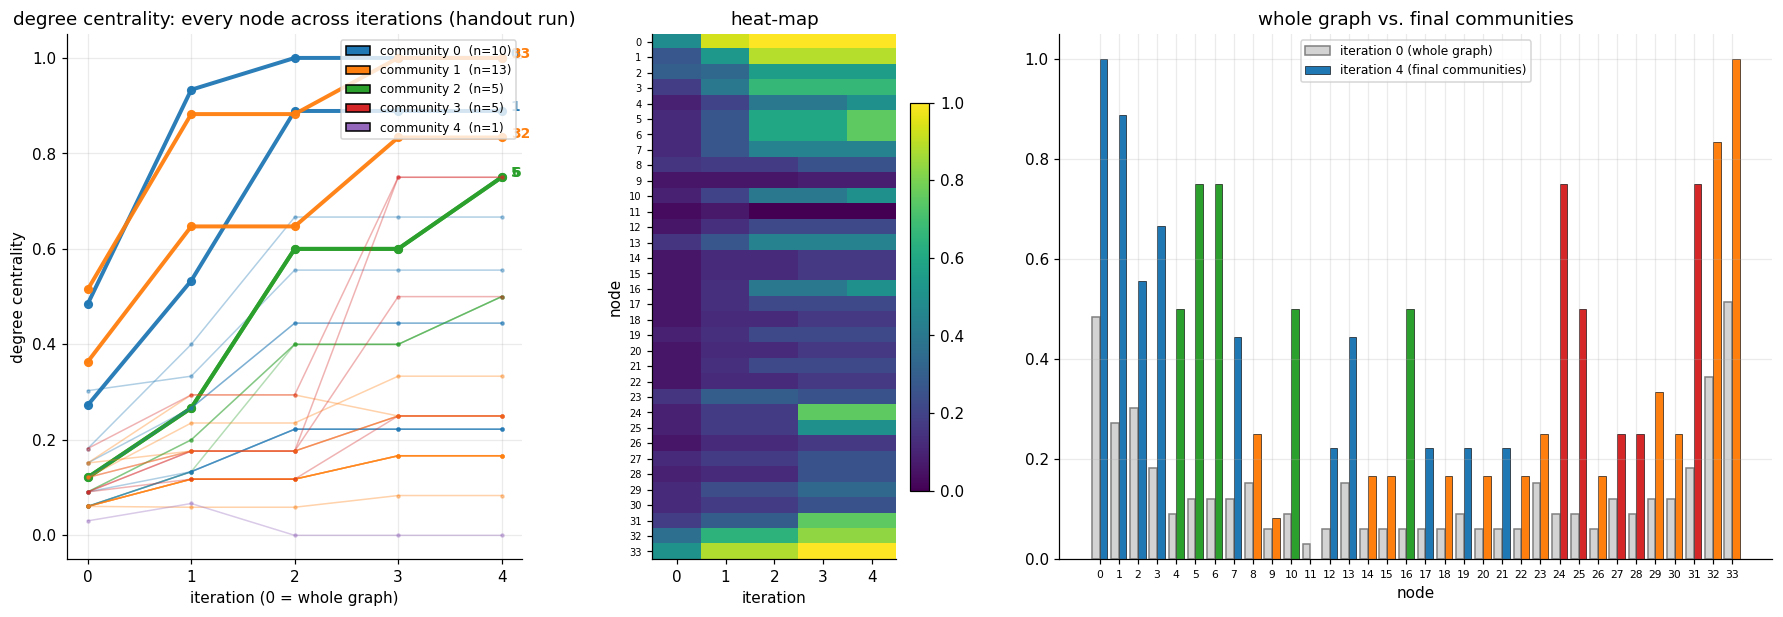

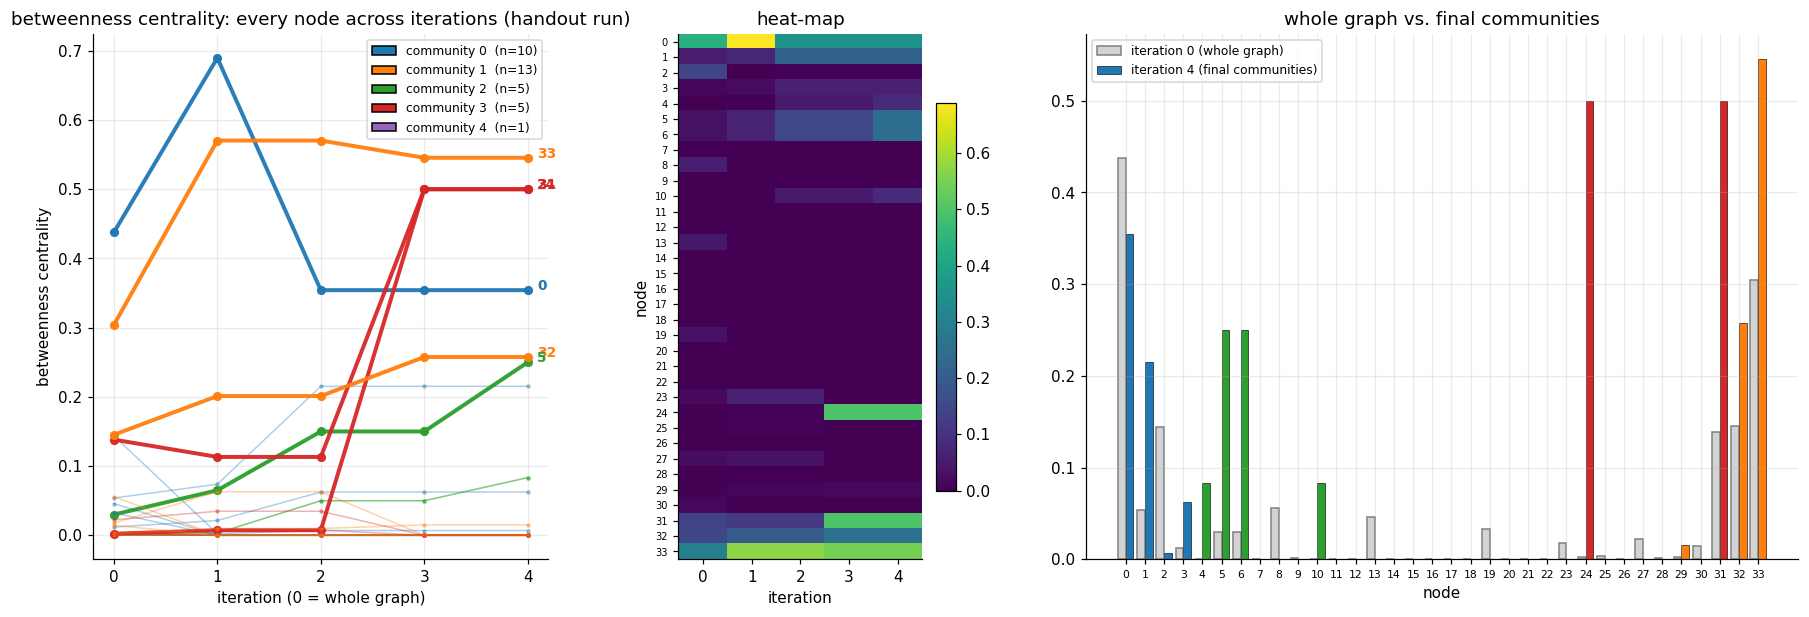

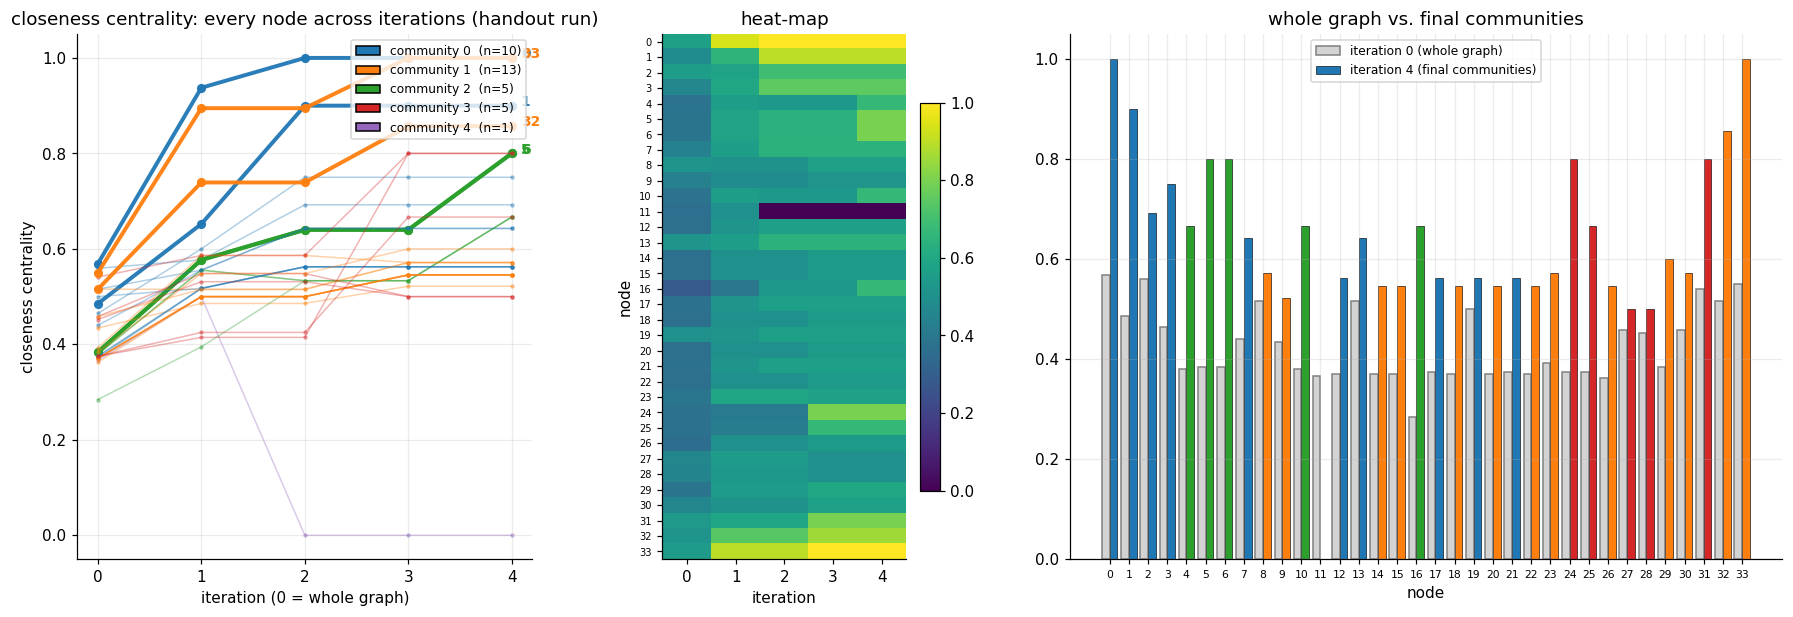

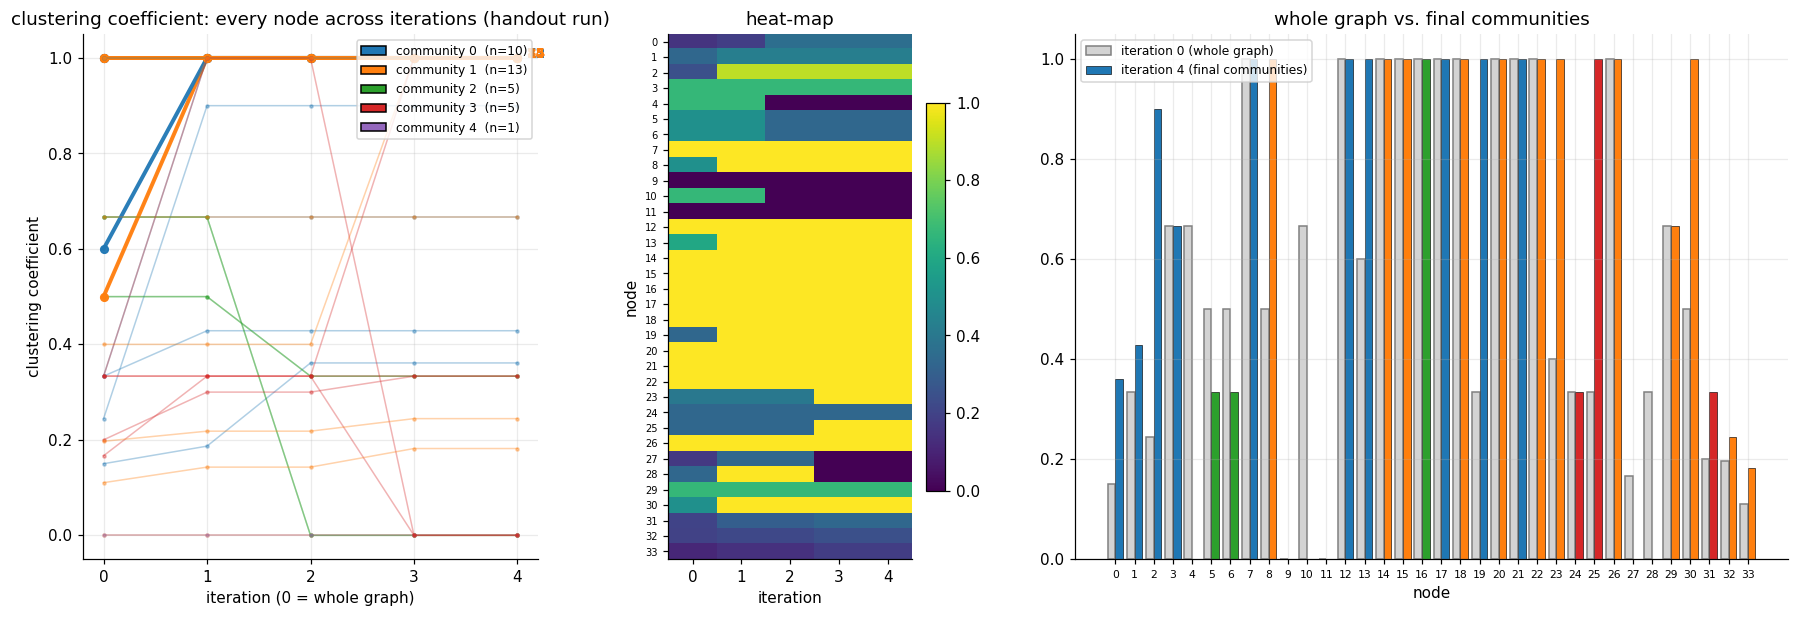

In [ ]:
def plot_metric_evolution(tables, name, history, tag=""):
    df = tables[name]; its = list(df.columns); final = history[-1]["labels"]
    fig = plt.figure(figsize=(20, 6.2)); gs = fig.add_gridspec(1, 3, width_ratios=[1.15, .7, 1.8], wspace=.27)
    ax = fig.add_subplot(gs[0]); top = list(df.max(axis=1).nlargest(6).index)
    for v in df.index:
        isTop = v in top
        ax.plot(its, df.loc[v].values, color=PALETTE[final[v] % 10], alpha=.95 if isTop else .35, lw=2.6 if isTop else 1.0,
                marker="o", ms=5 if isTop else 2)
    for v in top: ax.annotate(str(v), (its[-1], df.loc[v, its[-1]]), xytext=(6, 0), textcoords="offset points", fontsize=9, fontweight="bold", color=PALETTE[final[v] % 10])
    ax.set_xticks(its); ax.set_xlabel("iteration (0 = whole graph)"); ax.set_ylabel(name)
    ax.set_title(f"{name}: every node across iterations {tag}"); community_legend(final, ax, loc="upper right")
    ax2 = fig.add_subplot(gs[1]); im = ax2.imshow(df.values, aspect="auto", cmap="viridis"); ax2.grid(False)
    ax2.set_xticks(range(len(its))); ax2.set_xticklabels(its); ax2.set_yticks(range(len(df))); ax2.set_yticklabels(df.index, fontsize=6.5)
    ax2.set_xlabel("iteration"); ax2.set_ylabel("node"); ax2.set_title("heat-map"); plt.colorbar(im, ax=ax2, fraction=.07)
    ax3 = fig.add_subplot(gs[2]); x = np.arange(len(df)); wd = .4
    ax3.bar(x - wd / 2, df[its[0]], wd, color="lightgrey", edgecolor="grey", label="iteration 0 (whole graph)")
    ax3.bar(x + wd / 2, df[its[-1]], wd, color=[PALETTE[final[v] % 10] for v in df.index], edgecolor="k", lw=.4, label=f"iteration {its[-1]} (final communities)")
    ax3.set_xticks(x); ax3.set_xticklabels(df.index, fontsize=7); ax3.set_xlabel("node"); ax3.legend(fontsize=8); ax3.set_title("whole graph vs. final communities")
    plt.show()

for name in METRICS: plot_metric_evolution(TABLES, name, HIST, tag="(handout run)")

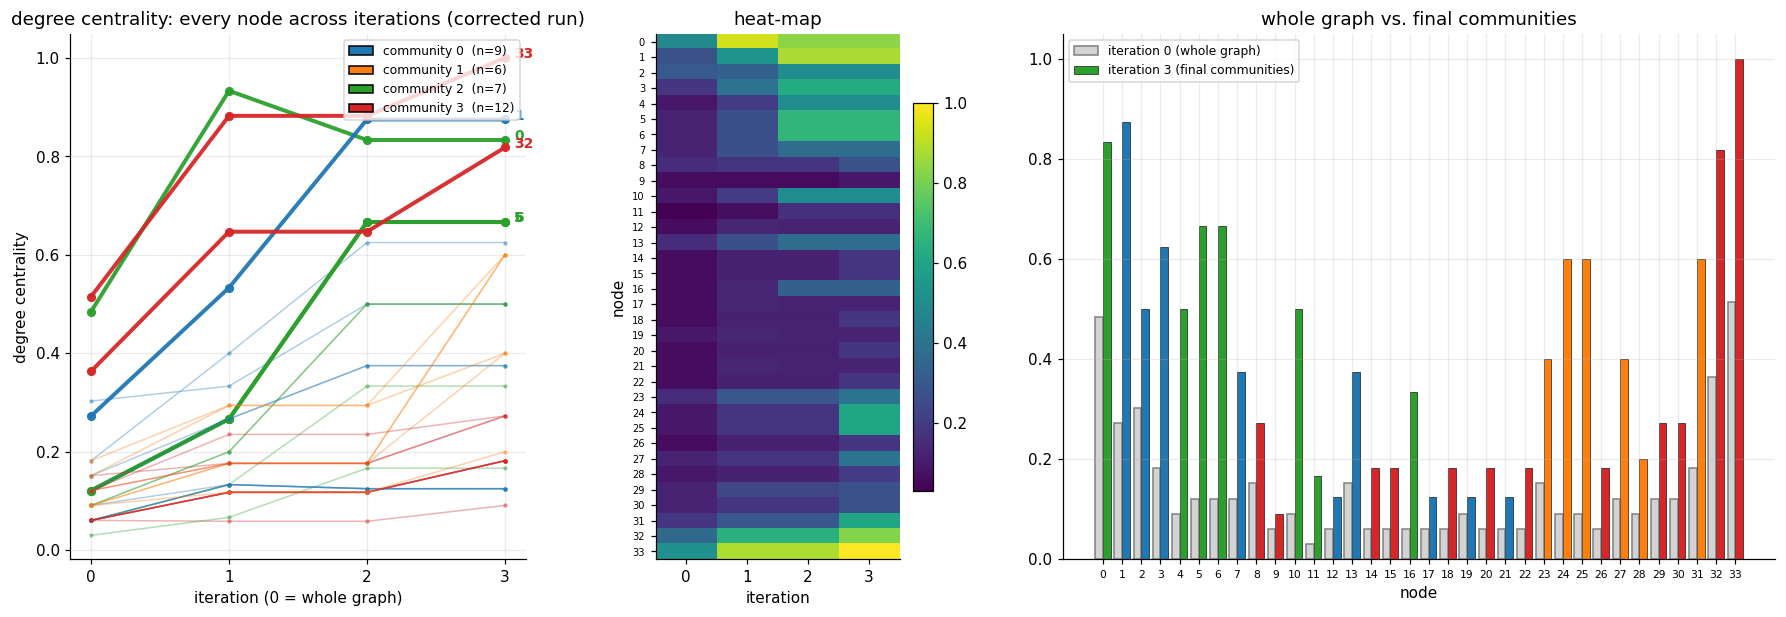

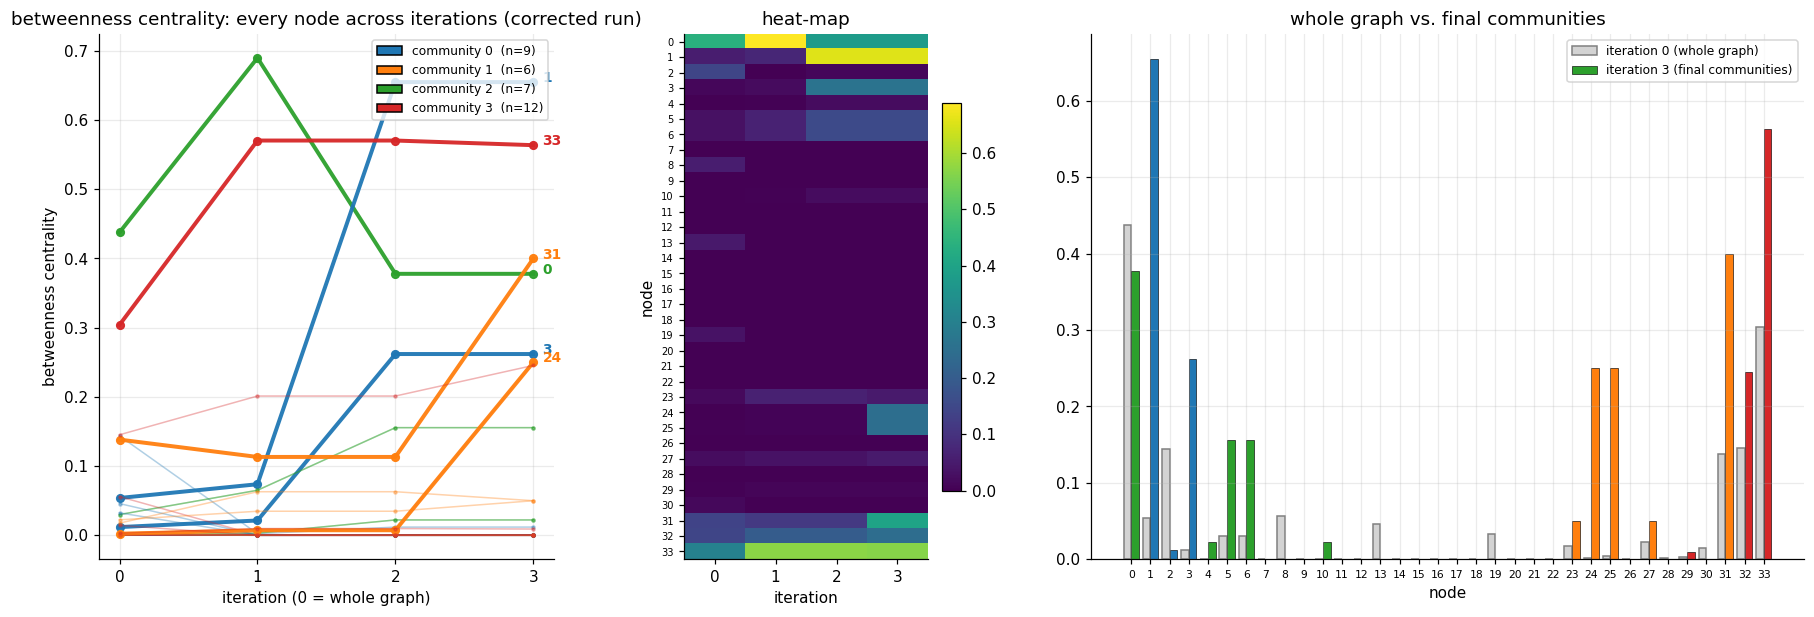

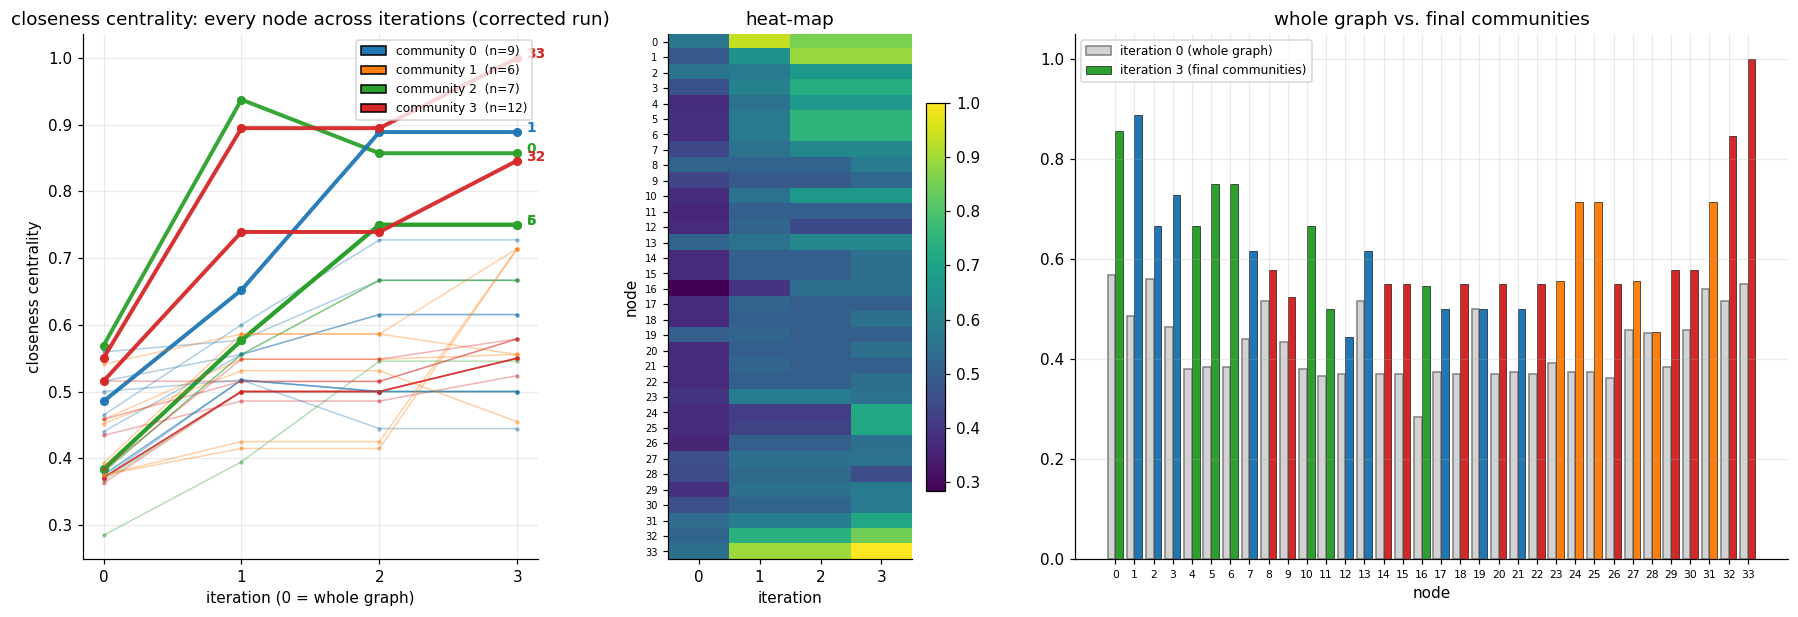

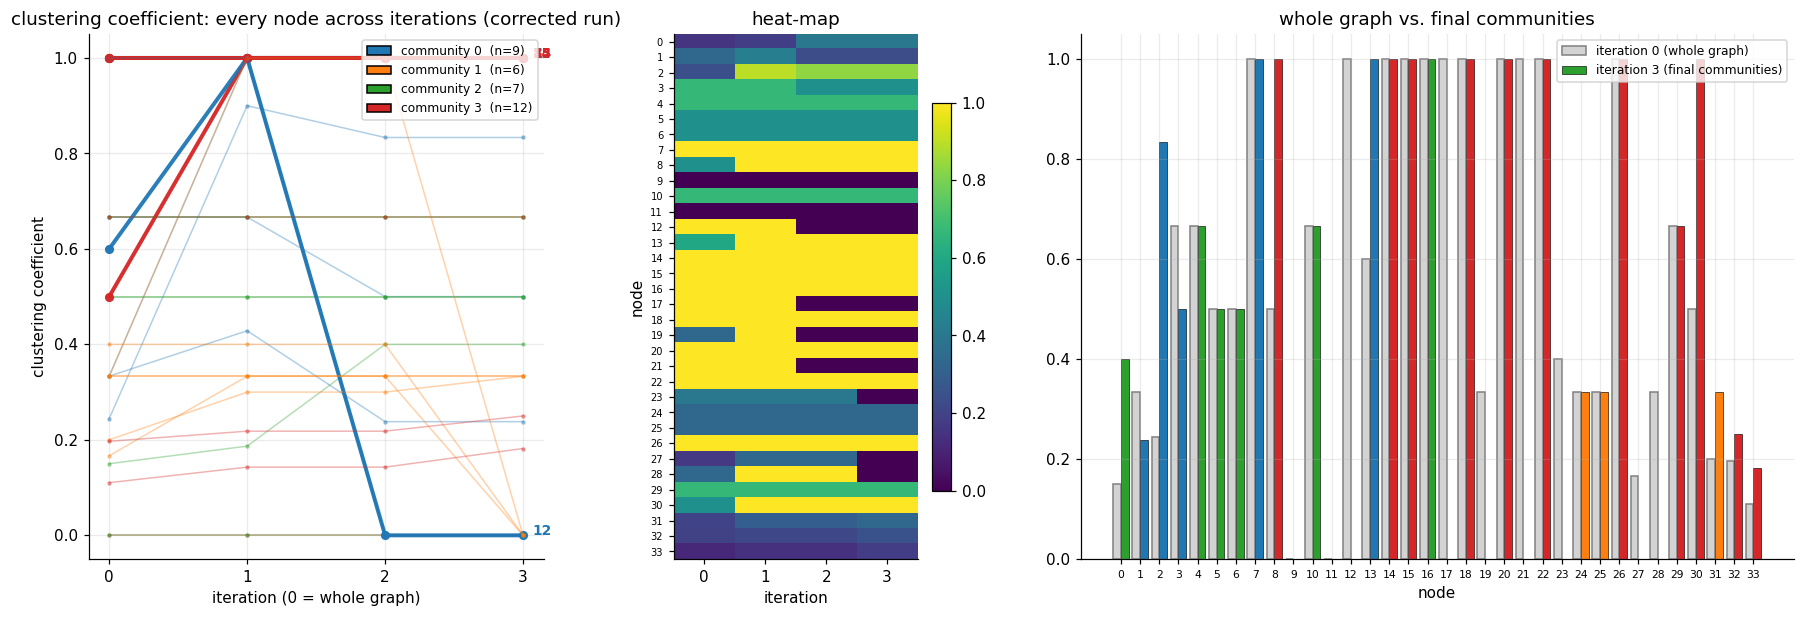

In [ ]:
# Same four plots for the corrected variant (4 communities) — a second, independent set of iterations
for name in METRICS: plot_metric_evolution(TABLES_C, name, RES["corrected"]["history"], tag="(corrected run)")

In [ ]:
# Which nodes stay central?  Top-5 membership for every metric and iteration
TOPK = 5
rows, tops = [], {}
for name, df in TABLES.items():
    sets = {it: list(df[it].sort_values(ascending=False, kind="stable").index[:TOPK]) for it in df.columns}
    tops[name] = sets
    always = set.intersection(*[set(s) for s in sets.values()]); ever = set.union(*[set(s) for s in sets.values()])
    rows.append({"metric": name, **{f"top-{TOPK} @ it {it}": [int(v) for v in s] for it, s in sets.items()},
                 f"always in top-{TOPK}": sorted(int(v) for v in always), "ever in top-5": len(ever)})
print(pd.DataFrame(rows).set_index("metric").T.to_string())

metric            degree centrality betweenness centrality closeness centrality clustering coefficient
top-5 @ it 0      [33, 0, 32, 2, 1]     [0, 33, 32, 2, 31]    [0, 2, 33, 31, 8]    [7, 12, 14, 15, 16]
top-5 @ it 1      [0, 33, 32, 1, 3]     [0, 33, 32, 31, 1]    [0, 33, 32, 1, 3]     [7, 8, 12, 13, 14]
top-5 @ it 2      [0, 1, 33, 3, 32]      [33, 0, 1, 32, 5]    [0, 1, 33, 3, 32]     [7, 8, 12, 13, 14]
top-5 @ it 3     [0, 33, 1, 32, 24]    [33, 24, 31, 0, 32]   [0, 33, 1, 32, 24]     [7, 8, 12, 13, 14]
top-5 @ it 4      [0, 33, 1, 32, 5]    [33, 24, 31, 0, 32]    [0, 33, 1, 32, 5]     [7, 8, 12, 13, 14]
always in top-5      [0, 1, 32, 33]            [0, 32, 33]              [0, 33]            [7, 12, 14]
ever in top-5                     8                      8                   10                      7


    mean rank (all metrics, all iterations)  best rank ever  worst rank ever  degree  final community
0                                      7.55             1.0             31.0      16                0
1                                      8.75             2.0             24.0       9                0
33                                     8.75             1.0             32.0      17                1
13                                     9.55             1.0             17.0       5                0
32                                    10.10             3.0             30.0      12                1
7                                     10.15             1.0             23.0       4                0
3                                     10.30             4.0             19.0       6                0
31                                    10.95             2.0             29.0       6                3
2                                     11.55             2.0             27.0      

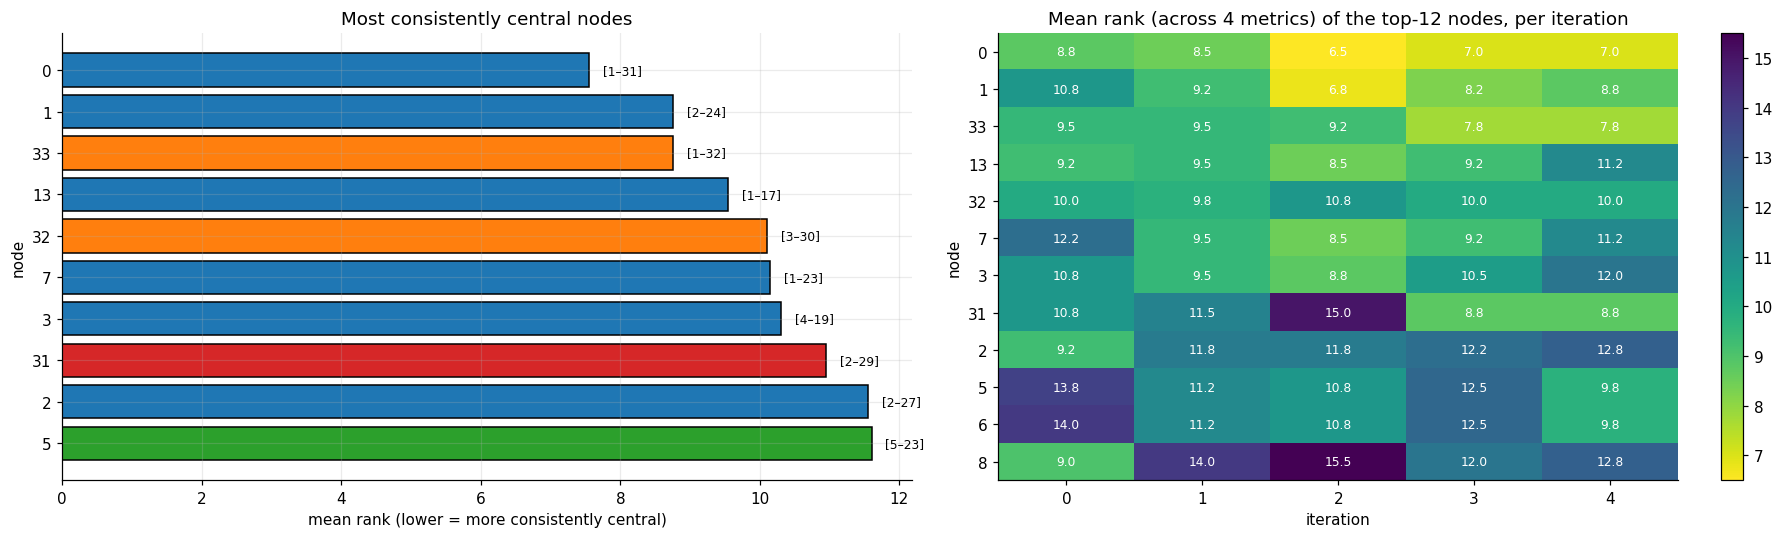

In [ ]:
# One summary score: rank of each node among 34 on every metric & iteration (1 = most central); average over all of them
rank_frames = {name: df.rank(ascending=False, method="min") for name, df in TABLES.items()}
mean_rank = sum(rank_frames.values()) / len(rank_frames)                       # node × iteration
summary = pd.DataFrame({"mean rank (all metrics, all iterations)": mean_rank.mean(axis=1),
                        "best rank ever": pd.concat(rank_frames.values(), axis=1).min(axis=1),
                        "worst rank ever": pd.concat(rank_frames.values(), axis=1).max(axis=1),
                        "degree": k.astype(int), "final community": HIST[-1]["labels"]}).sort_values("mean rank (all metrics, all iterations)")
print(summary.head(12).round(2).to_string())

fig, axs = plt.subplots(1, 2, figsize=(17, 5))
t10 = summary.head(10)[::-1]
axs[0].barh([str(i) for i in t10.index], t10.iloc[:, 0], color=[PALETTE[c % 10] for c in t10["final community"]], edgecolor="k")
axs[0].set_xlabel("mean rank (lower = more consistently central)"); axs[0].set_ylabel("node"); axs[0].set_title("Most consistently central nodes")
for i, (_, r) in enumerate(t10.iterrows()): axs[0].text(r.iloc[0] + .2, i, f"[{int(r['best rank ever'])}–{int(r['worst rank ever'])}]", va="center", fontsize=8)
rk = mean_rank.loc[summary.index[:12]]
im = axs[1].imshow(rk.values, aspect="auto", cmap="viridis_r"); axs[1].grid(False)
axs[1].set_yticks(range(len(rk))); axs[1].set_yticklabels(rk.index); axs[1].set_xticks(range(rk.shape[1])); axs[1].set_xticklabels(rk.columns)
axs[1].set_xlabel("iteration"); axs[1].set_ylabel("node"); axs[1].set_title("Mean rank (across 4 metrics) of the top-12 nodes, per iteration"); plt.colorbar(im, ax=axs[1])
for (i, j), v in np.ndenumerate(rk.values): axs[1].text(j, i, f"{v:.1f}", ha="center", va="center", color="w", fontsize=8)
plt.tight_layout(); plt.show()

                metric  iteration  ρ vs iteration 0  ρ vs previous
     degree centrality          1             0.927          0.927
     degree centrality          2             0.777          0.923
     degree centrality          3             0.839          0.863
     degree centrality          4             0.813          0.992
betweenness centrality          1             0.716          0.716
betweenness centrality          2             0.693          0.987
betweenness centrality          3             0.616          0.860
betweenness centrality          4             0.609          0.998
  closeness centrality          1             0.736          0.736
  closeness centrality          2             0.693          0.905
  closeness centrality          3             0.614          0.653
  closeness centrality          4             0.526          0.832
clustering coefficient          1             0.815          0.815
clustering coefficient          2             0.688          0

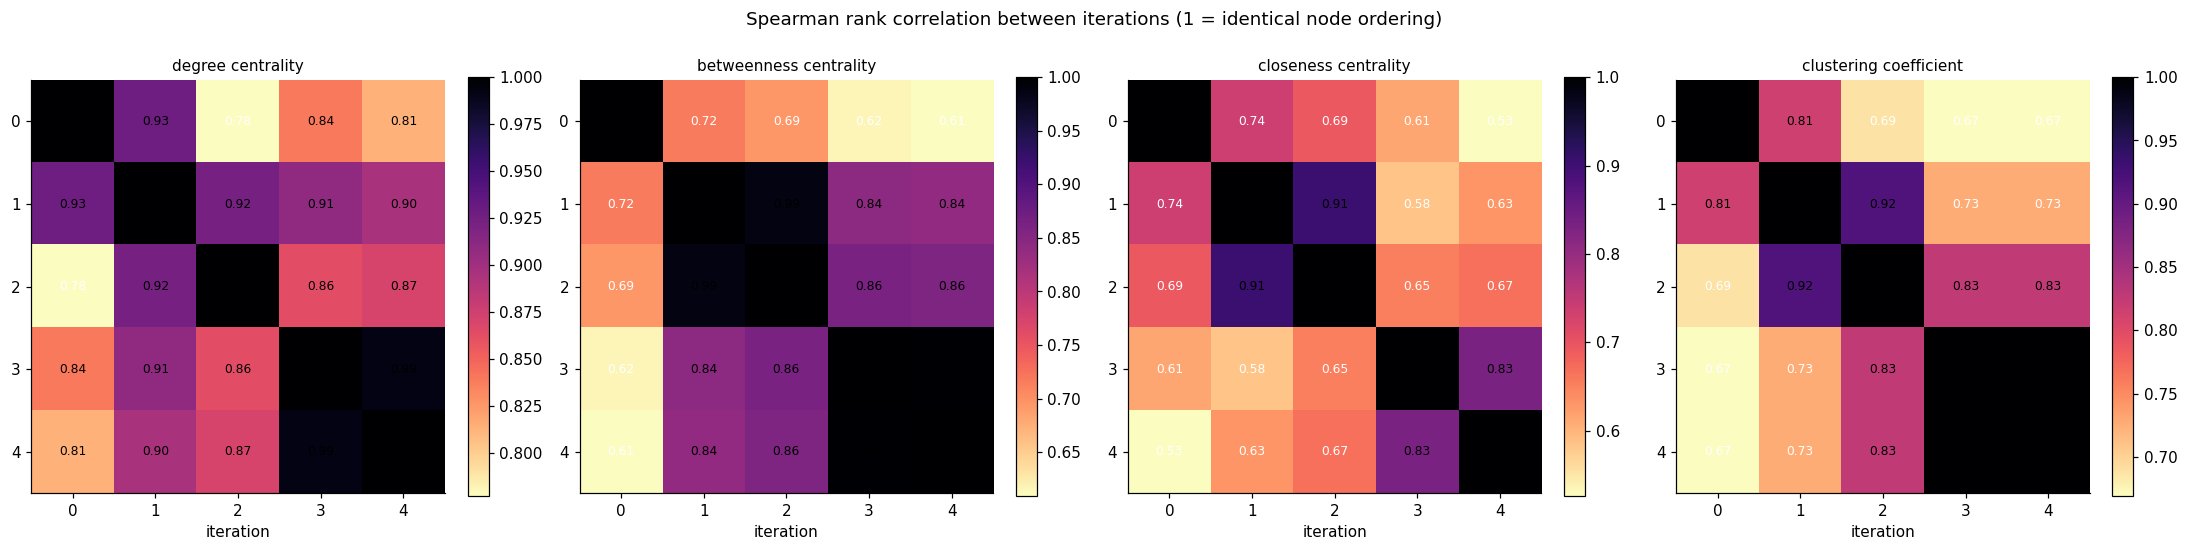

In [ ]:
# How stable is the *ordering* of nodes?  Spearman correlation of each iteration with iteration 0 and with the previous iteration
rows = []
for name, df in TABLES.items():
    for it in df.columns[1:]:
        rows.append({"metric": name, "iteration": it, "ρ vs iteration 0": df[0].corr(df[it], method="spearman"),
                     "ρ vs previous": df[it - 1].corr(df[it], method="spearman")})
rho = pd.DataFrame(rows); print(rho.round(3).to_string(index=False))

fig, axs = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (name, df) in zip(axs, TABLES.items()):
    C = df.corr(method="spearman"); im = ax.imshow(C.values, vmin=C.values.min(), vmax=1, cmap="magma_r"); ax.grid(False)
    ax.set_xticks(range(len(C))); ax.set_yticks(range(len(C))); ax.set_xticklabels(C.columns); ax.set_yticklabels(C.columns)
    for (i, j), v in np.ndenumerate(C.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="w" if v < .8 else "k")
    ax.set_title(name, fontsize=10); ax.set_xlabel("iteration"); plt.colorbar(im, ax=ax, fraction=.046)
plt.suptitle("Spearman rank correlation between iterations (1 = identical node ordering)", y=1.03); plt.tight_layout(); plt.show()

handout run:
            # communities       Q  mean degree centrality  mean betweenness centrality  mean closeness centrality  mean clustering coefficient
iteration                                                                                                                                    
0                      1 -0.0000                  0.1390                       0.0440                     0.4265                       0.5706
1                      2  0.3715                  0.2505                       0.0568                     0.5558                       0.6836
2                      3  0.3898                  0.3355                       0.0602                     0.5749                       0.6397
3                      4  0.4081                  0.4056                       0.0840                     0.6174                       0.6407
4                      5  0.4094                  0.4232                       0.0919                     0.6385                      

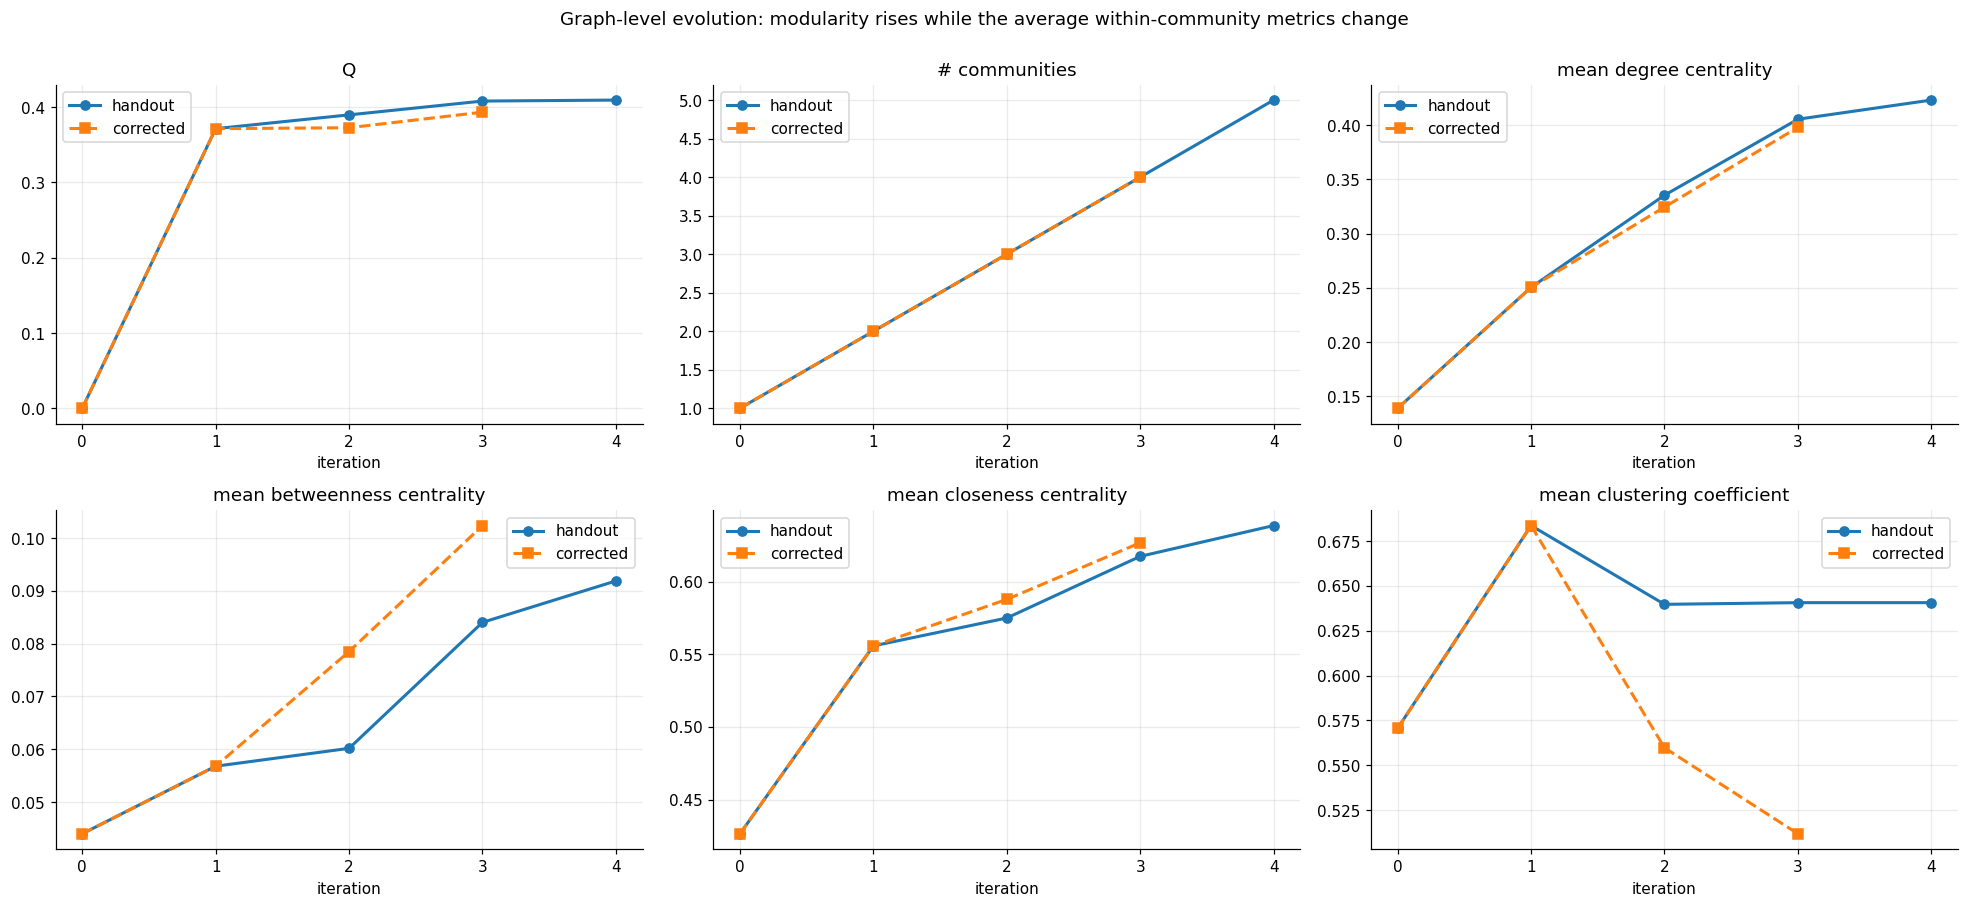

In [ ]:
# Graph-level summary per iteration: Q, number of communities, mean of each metric
def summary_table(tables, history):
    return pd.DataFrame({"iteration": [h["iteration"] for h in history], "# communities": [len(np.unique(h["labels"])) for h in history],
                         "Q": [h["Q"] for h in history], **{f"mean {n}": tables[n].mean(axis=0).values for n in tables}}).set_index("iteration")
ST = summary_table(TABLES, HIST); ST_C = summary_table(TABLES_C, RES["corrected"]["history"])
print("handout run:\n", ST.round(4).to_string(), "\n\ncorrected run:\n", ST_C.round(4).to_string())

fig, axs = plt.subplots(2, 3, figsize=(18, 8.2)); axs = axs.ravel()
for ax, col in zip(axs, ["Q", "# communities"] + [f"mean {n}" for n in TABLES]):
    ax.plot(ST.index, ST[col], "o-", lw=2, label="handout"); ax.plot(ST_C.index, ST_C[col], "s--", lw=2, label="corrected")
    ax.set_xlabel("iteration"); ax.set_title(col); ax.set_xticks(sorted(set(ST.index) | set(ST_C.index))); ax.legend()
plt.suptitle("Graph-level evolution: modularity rises while the average within-community metrics change", y=1.0); plt.tight_layout(); plt.show()

## Part 10 — How community structure shapes the metrics

Three lenses:
1. **Coverage vs. null model per iteration** — the textbook form $Q=\sum_c\big(e_c/m-(K_c/2m)^2\big)$ (connects the metrics' changes to *what is being cut*).
2. **Participation coefficient** $P_i=1-\sum_c(k_i^{(c)}/k_i)^2$ ($0$ = all neighbours in one community; large = neighbours spread over many) — a direct measure of "brokerage" to compare with betweenness.
3. **Global vs. community-restricted** values for every node.

In [ ]:
def edge_table(history):
    rows = []
    for h in history:
        lab = h["labels"]; same_ = np.array([lab[u] == lab[v] for u, v in G.edges()]); within = int(same_.sum())
        comms = np.unique(lab); Kc = np.array([k[lab == c].sum() for c in comms]); exp_cov = float(((Kc / (2 * m)) ** 2).sum())
        rows.append({"iteration": h["iteration"], "# communities": len(comms), "edges inside": within, "edges cut": m - within,
                     "coverage e_in/m": within / m, "null-model coverage Σ(K_c/2m)²": exp_cov, "Q = coverage − null": within / m - exp_cov, "Q (via B)": h["Q"]})
    return pd.DataFrame(rows).set_index("iteration")
ET = edge_table(HIST); print(ET.round(4).to_string())
assert np.allclose(ET["Q = coverage − null"], ET["Q (via B)"]); print("\n✔ the two formulas for Q agree at every iteration")

           # communities  edges inside  edges cut  coverage e_in/m  null-model coverage Σ(K_c/2m)²  Q = coverage − null  Q (via B)
iteration                                                                                                                         
0                      1            78          0           1.0000                          1.0000               0.0000    -0.0000
1                      2            68         10           0.8718                          0.5003               0.3715     0.3715
2                      3            63         15           0.8077                          0.4179               0.3898     0.3898
3                      4            57         21           0.7308                          0.3226               0.4081     0.4081
4                      5            57         21           0.7308                          0.3213               0.4094     0.4094

✔ the two formulas for Q agree at every iteration


In [ ]:
final = HIST[-1]["labels"]
def participation(labels):
    rows = []
    for i in nodes:
        nb_ = list(G.neighbors(i)); cnt = pd.Series(labels[nb_]).value_counts()
        rows.append({"node": i, "community": int(labels[i]), "degree": int(k[i]), "k_in": int(cnt.get(labels[i], 0)),
                     "k_out": int(k[i] - cnt.get(labels[i], 0)), "participation P_i": 1 - float(((cnt / k[i]) ** 2).sum())})
    return pd.DataFrame(rows).set_index("node")
PART = participation(final)
PART["global betweenness"] = TABLES["betweenness centrality"][0]; PART["within-comm. betweenness"] = TABLES["betweenness centrality"][HIST[-1]["iteration"]]
PART["global degree c."] = TABLES["degree centrality"][0]; PART["within-comm. degree c."] = TABLES["degree centrality"][HIST[-1]["iteration"]]
print("Top-10 'bridging' nodes by participation coefficient:\n", PART.sort_values("participation P_i", ascending=False).head(10).round(3).to_string())
print("\nSpearman(participation, global betweenness) =", round(PART["participation P_i"].corr(PART["global betweenness"], method="spearman"), 3))
print("Nodes with every neighbour inside their community (P=0):", [int(v) for v in PART.index[PART["participation P_i"] == 0]])
print("Fraction of all edges that are inside communities (final):", round(ET["coverage e_in/m"].iloc[-1], 3))

Top-10 'bridging' nodes by participation coefficient:
       community  degree  k_in  k_out  participation P_i  global betweenness  within-comm. betweenness  global degree c.  within-comm. degree c.
node                                                                                                                                           
28            3       3     1      2              0.667               0.002                     0.000             0.091                   0.250
27            3       4     1      3              0.625               0.022                     0.000             0.121                   0.250
2             0      10     5      5              0.620               0.144                     0.007             0.303                   0.556
31            3       6     3      3              0.611               0.138                     0.500             0.182                   0.750
0             0      16     9      7              0.609               0.438      

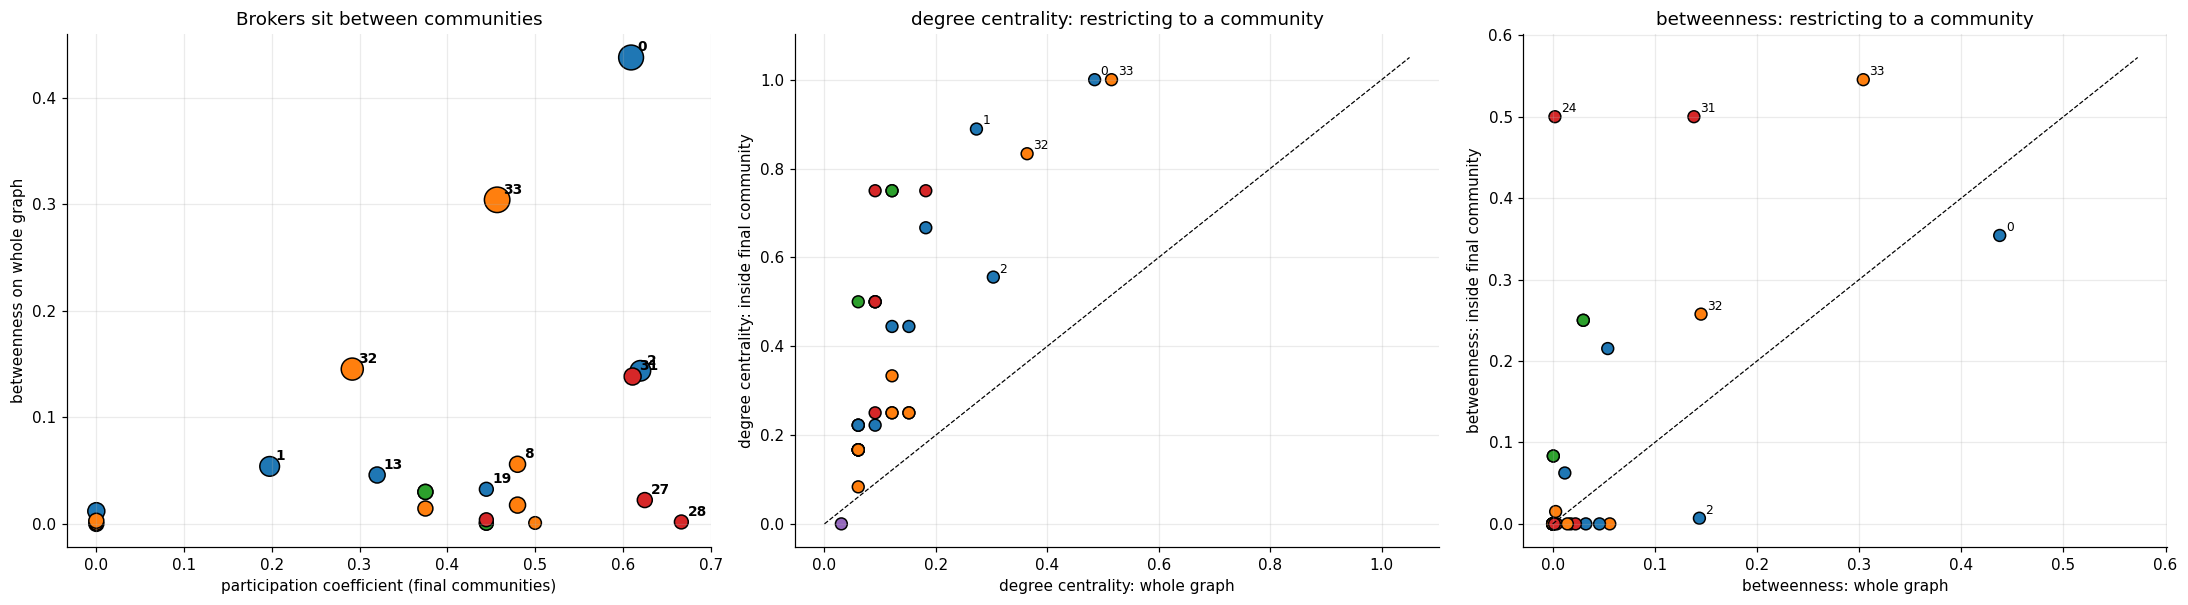

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5.6))
ax = axs[0]
ax.scatter(PART["participation P_i"], PART["global betweenness"], c=[PALETTE[c % 10] for c in PART.community], s=40 + 14 * PART.degree, edgecolor="k")
for v, r in PART.iterrows():
    if r["global betweenness"] > .03 or r["participation P_i"] > .55: ax.annotate(str(v), (r["participation P_i"], r["global betweenness"]), xytext=(4, 4), textcoords="offset points", fontsize=9, fontweight="bold")
ax.set_xlabel("participation coefficient (final communities)"); ax.set_ylabel("betweenness on whole graph"); ax.set_title("Brokers sit between communities")
for ax, (a, b, ttl) in zip(axs[1:], [("global degree c.", "within-comm. degree c.", "degree centrality"), ("global betweenness", "within-comm. betweenness", "betweenness")]):
    ax.scatter(PART[a], PART[b], c=[PALETTE[c % 10] for c in PART.community], s=60, edgecolor="k")
    lim = max(PART[a].max(), PART[b].max()) * 1.05; ax.plot([0, lim], [0, lim], "k--", lw=.8)
    for v, r in PART.iterrows():
        if r[a] > np.quantile(PART[a], .85) or r[b] > np.quantile(PART[b], .88): ax.annotate(str(v), (r[a], r[b]), xytext=(4, 3), textcoords="offset points", fontsize=8)
    ax.set_xlabel(f"{ttl}: whole graph"); ax.set_ylabel(f"{ttl}: inside final community"); ax.set_title(f"{ttl}: restricting to a community")
plt.tight_layout(); plt.show()

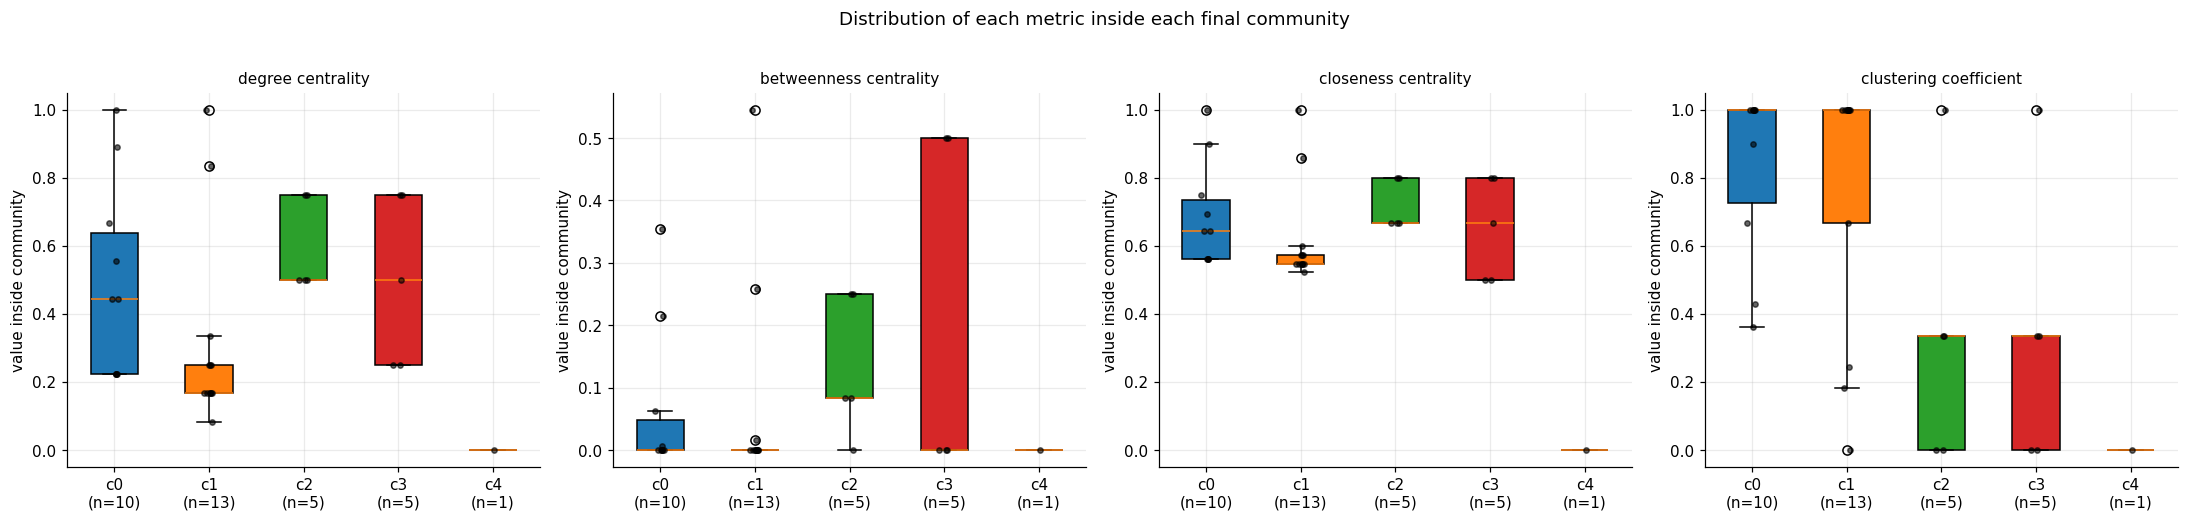

Largest changes (final minus whole-graph) per metric:
  degree centrality        biggest rise: node 24 (+0.659)   biggest fall: node 11 (-0.030)
  betweenness centrality   biggest rise: node 24 (+0.498)   biggest fall: node  2 (-0.137)
  closeness centrality     biggest rise: node 33 (+0.450)   biggest fall: node 11 (-0.367)
  clustering coefficient   biggest rise: node 19 (+0.667)   biggest fall: node  4 (-0.667)


In [ ]:
# Distribution of each metric by final community (iteration = final) and what changes relative to the whole graph
fl_it = HIST[-1]["iteration"]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (name, df) in zip(axs, TABLES.items()):
    comms = sorted(np.unique(final)); data = [df.loc[np.where(final == c)[0], fl_it].values for c in comms]
    bp = ax.boxplot(data, patch_artist=True); ax.set_xticks(range(1, len(comms) + 1)); ax.set_xticklabels([f"c{c}\n(n={len(d)})" for c, d in zip(comms, data)])
    for patch, c in zip(bp["boxes"], comms): patch.set_facecolor(PALETTE[c % 10])
    for i, (c, d) in enumerate(zip(comms, data)): ax.scatter(np.random.default_rng(1).normal(i + 1, .04, len(d)), d, s=12, c="k", alpha=.6, zorder=3)
    ax.set_title(name, fontsize=10); ax.set_ylabel("value inside community")
plt.suptitle("Distribution of each metric inside each final community", y=1.02); plt.tight_layout(); plt.show()

chg = pd.DataFrame({name: (df[fl_it] - df[0]) for name, df in TABLES.items()})
print("Largest changes (final minus whole-graph) per metric:")
for name in chg: print(f"  {name:<24} biggest rise: node {int(chg[name].idxmax()):>2} ({chg[name].max():+.3f})   biggest fall: node {int(chg[name].idxmin()):>2} ({chg[name].min():+.3f})")

## Part 11 — Comparison with other community-detection methods

We place our from-scratch method next to NetworkX's standard algorithms (greedy modularity = Clauset–Newman–Moore, Louvain, asynchronous label propagation, Girvan–Newman) using: number of communities, modularity $Q$, **purity** with respect to the real factions, **NMI** and **ARI**. NMI and ARI are implemented here so that no extra library is required.

                                # communities       Q  purity vs factions  NMI vs factions  ARI vs factions
Spectral bisection (1 split)              2.0  0.3715              0.9706           0.8372           0.8823
Recursive spectral — handout              5.0  0.4094              0.9706           0.5646           0.4463
Recursive spectral — corrected            4.0  0.3934              0.9706           0.5792           0.4352
Greedy modularity (CNM)                   3.0  0.3807              0.9412           0.5646           0.5684
Louvain                                   4.0  0.4188              0.9412           0.4900           0.3922
Label propagation (async)                 2.0  0.3600              0.9412           0.7324           0.7717
Girvan–Newman (best-Q level)              5.0  0.4013              0.9412           0.4851           0.3916

Q cross-check with networkx for every row: True


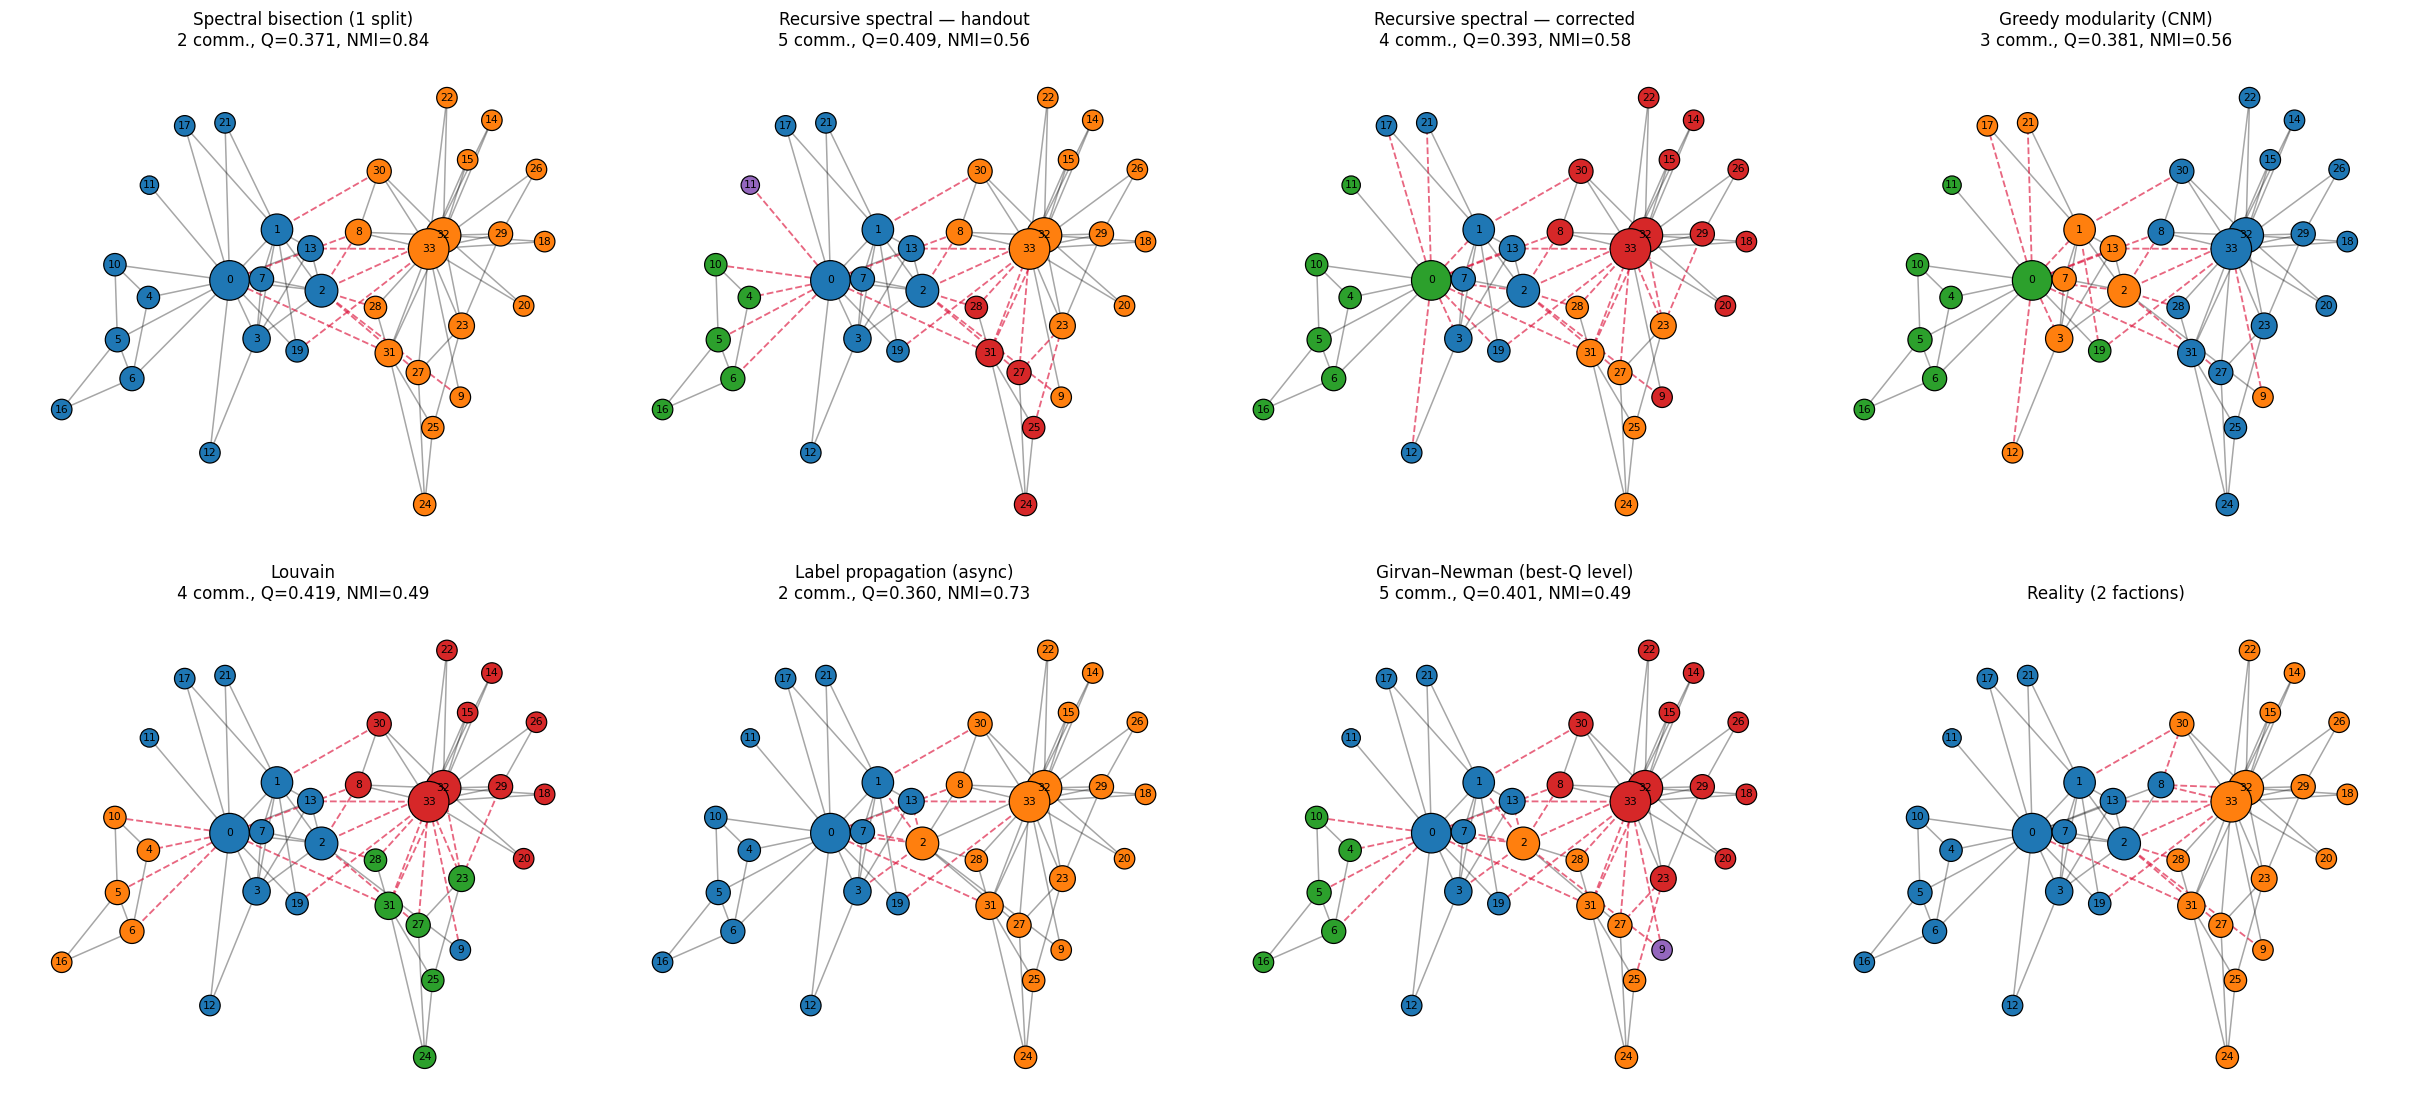

In [ ]:
def contingency(a, b): return pd.crosstab(np.asarray(a), np.asarray(b)).values.astype(float)
def nmi(a, b):
    C = contingency(a, b); N = C.sum(); P = C / N; pa, pb = P.sum(1), P.sum(0)
    nz = P > 0; mi = (P[nz] * np.log(P[nz] / np.outer(pa, pb)[nz])).sum()
    ha, hb = -(pa[pa > 0] * np.log(pa[pa > 0])).sum(), -(pb[pb > 0] * np.log(pb[pb > 0])).sum()
    return float(mi / ((ha + hb) / 2)) if (ha + hb) > 0 else 1.0
def ari(a, b):
    C = contingency(a, b); N = C.sum(); c2 = lambda x: x * (x - 1) / 2
    sum_ij, sum_a, sum_b = c2(C).sum(), c2(C.sum(1)).sum(), c2(C.sum(0)).sum(); exp = sum_a * sum_b / c2(N)
    return float((sum_ij - exp) / (0.5 * (sum_a + sum_b) - exp))
def purity(lab, ref): C = contingency(lab, ref); return float(C.max(axis=1).sum() / C.sum())

girvan = [set(c) for c in max(nx.community.girvan_newman(G), key=lambda part: nx.community.modularity(G, part, weight=None))]
algos = {
    "Spectral bisection (1 split)": HIST[1]["labels"],
    "Recursive spectral — handout": RES["handout"]["labels"],
    "Recursive spectral — corrected": RES["corrected"]["labels"],
    "Greedy modularity (CNM)": labels_from_communities(nx.community.greedy_modularity_communities(G, weight=None), n),
    "Louvain": labels_from_communities(nx.community.louvain_communities(G, seed=SEED, weight=None), n),
    "Label propagation (async)": labels_from_communities(list(nx.community.asyn_lpa_communities(G, seed=SEED, weight=None)), n),
    "Girvan–Newman (best-Q level)": labels_from_communities(girvan, n),
}
cmp_ = pd.DataFrame({name: {"# communities": len(np.unique(l)), "Q": Q_from_labels(B, l, m), "purity vs factions": purity(l, truth_labels),
                            "NMI vs factions": nmi(l, truth_labels), "ARI vs factions": ari(l, truth_labels)} for name, l in algos.items()}).T
print(cmp_.round(4).to_string())
print("\nQ cross-check with networkx for every row:", all(np.isclose(Q_from_labels(B, l, m), nx.community.modularity(G, [set(np.where(l == c)[0]) for c in np.unique(l)], weight=None)) for l in algos.values()))

fig, axs = plt.subplots(2, 4, figsize=(22, 10.2)); axs = axs.ravel()
for ax, (name, l) in zip(axs, algos.items()):
    draw_partition(G, pos, l, ax, f"{name}\n{len(np.unique(l))} comm., Q={Q_from_labels(B, l, m):.3f}, NMI={nmi(l, truth_labels):.2f}", font_size=7)
draw_partition(G, pos, truth_labels, axs[-1], "Reality (2 factions)", font_size=7)
plt.tight_layout(); plt.show()

Louvain over 30 seeds: Q min 0.3952, max 0.4198  (stochastic algorithm; it explores the same Q landscape)
Q after K communities with the corrected recursive algorithm: {1: -0.0, 2: 0.3715, 3: 0.3727, 4: 0.3934}


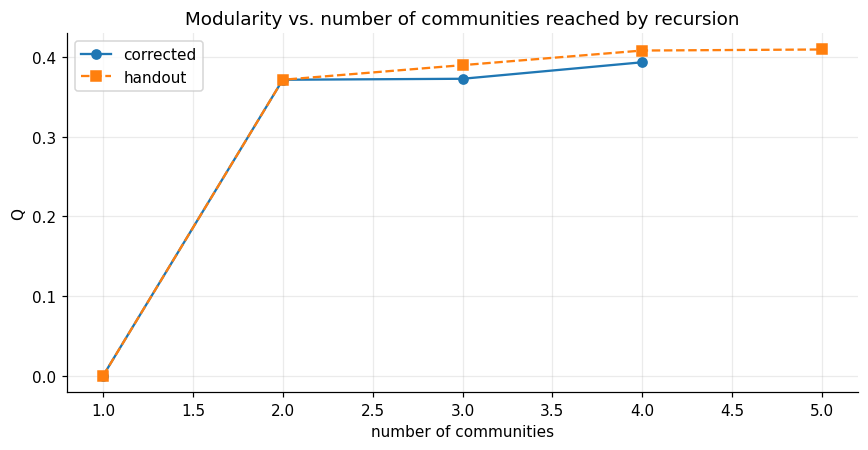

In [ ]:
# Resolution matters: modularity of the 'best' partition depends on how many groups we allow
louv_Q = [Q_from_labels(B, labels_from_communities(nx.community.louvain_communities(G, seed=s, weight=None), n), m) for s in range(30)]
print(f"Louvain over 30 seeds: Q min {min(louv_Q):.4f}, max {max(louv_Q):.4f}  (stochastic algorithm; it explores the same Q landscape)")
Qs_by_K = {}
for K in range(1, 8):
    # k-way partition obtained by stopping the recursive (corrected) algorithm after K-1 splits, then compared against Louvain
    hist = RES["corrected"]["history"]
    if K <= len(hist): Qs_by_K[K] = hist[K - 1]["Q"]
print("Q after K communities with the corrected recursive algorithm:", {K: round(v, 4) for K, v in Qs_by_K.items()})
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(list(Qs_by_K), list(Qs_by_K.values()), "o-", label="corrected"); ax.plot(ST.index + 1, ST["Q"], "s--", label="handout")
ax.set_xlabel("number of communities"); ax.set_ylabel("Q"); ax.set_title("Modularity vs. number of communities reached by recursion"); ax.legend(); plt.tight_layout(); plt.show()

## Part 12 — The same algorithm on other graphs

A method is only understood if we know when it works *and when it must not split*. We run the identical function on structured graphs where the answer is known (cliques joined by bridges, planted partitions), real small social networks, and two **negative controls** (a complete graph — no community structure whatsoever — and an Erdős–Rényi random graph).

In [ ]:
def prep(Gx):
    Gx = Gx.subgraph(max(nx.connected_components(Gx), key=len)).copy()          # largest connected component
    return nx.convert_node_labels_to_integers(Gx)

test_graphs = {
    "two K8 joined by an edge (barbell)": (nx.barbell_graph(8, 0), "2 communities"),
    "connected caveman 5 × K6": (nx.connected_caveman_graph(5, 6), "5 communities"),
    "ring of 6 cliques K5": (nx.ring_of_cliques(6, 5), "6 communities"),
    "planted partition 3×20 (p_in=.5, p_out=.03)": (nx.planted_partition_graph(3, 20, .5, .03, seed=SEED), "3 communities"),
    "Florentine families (15 nodes)": (nx.florentine_families_graph(), "unknown"),
    "Les Misérables co-appearance (77 nodes)": (nx.les_miserables_graph(), "unknown"),
    "complete graph K10 (negative control)": (nx.complete_graph(10), "no split expected"),
    "Erdős–Rényi G(60, 0.1) (negative control)": (nx.gnp_random_graph(60, .1, seed=SEED), "weak/no structure"),
}
rows, figs = [], {}
for name, (Gx, expect) in test_graphs.items():
    Gx = prep(Gx); Ax = nx.to_numpy_array(Gx, weight=None); out = {v: recursive_spectral(Ax, v) for v in ("handout", "corrected")}
    row = {"graph": name, "n": Gx.number_of_nodes(), "m": Gx.number_of_edges(), "expected": expect}
    for v, r in out.items():
        row[f"#comm {v}"] = len(np.unique(r["labels"])); row[f"Q {v}"] = round(Q_from_labels(r["B"], r["labels"], r["m"]), 4)
    lv = nx.community.louvain_communities(Gx, seed=SEED, weight=None); row["Q Louvain"] = round(nx.community.modularity(Gx, lv, weight=None), 4)
    rows.append(row); figs[name] = (Gx, out["corrected"]["labels"], out["handout"]["labels"])
print(pd.DataFrame(rows).set_index("graph").to_string())

                                              n    m           expected  #comm handout  Q handout  #comm corrected  Q corrected  Q Louvain
graph                                                                                                                                     
two K8 joined by an edge (barbell)           16   57      2 communities              2     0.4825                2       0.4825     0.4825
connected caveman 5 × K6                     30   75      5 communities              5     0.6911                6       0.6578     0.7333
ring of 6 cliques K5                         30   66      6 communities              6     0.6429                6       0.6458     0.7424
planted partition 3×20 (p_in=.5, p_out=.03)  60  314      3 communities              3     0.5305                3       0.5305     0.5305
Florentine families (15 nodes)               15   20            unknown              3     0.3638                3       0.3638     0.3987
Les Misérables co-appearanc

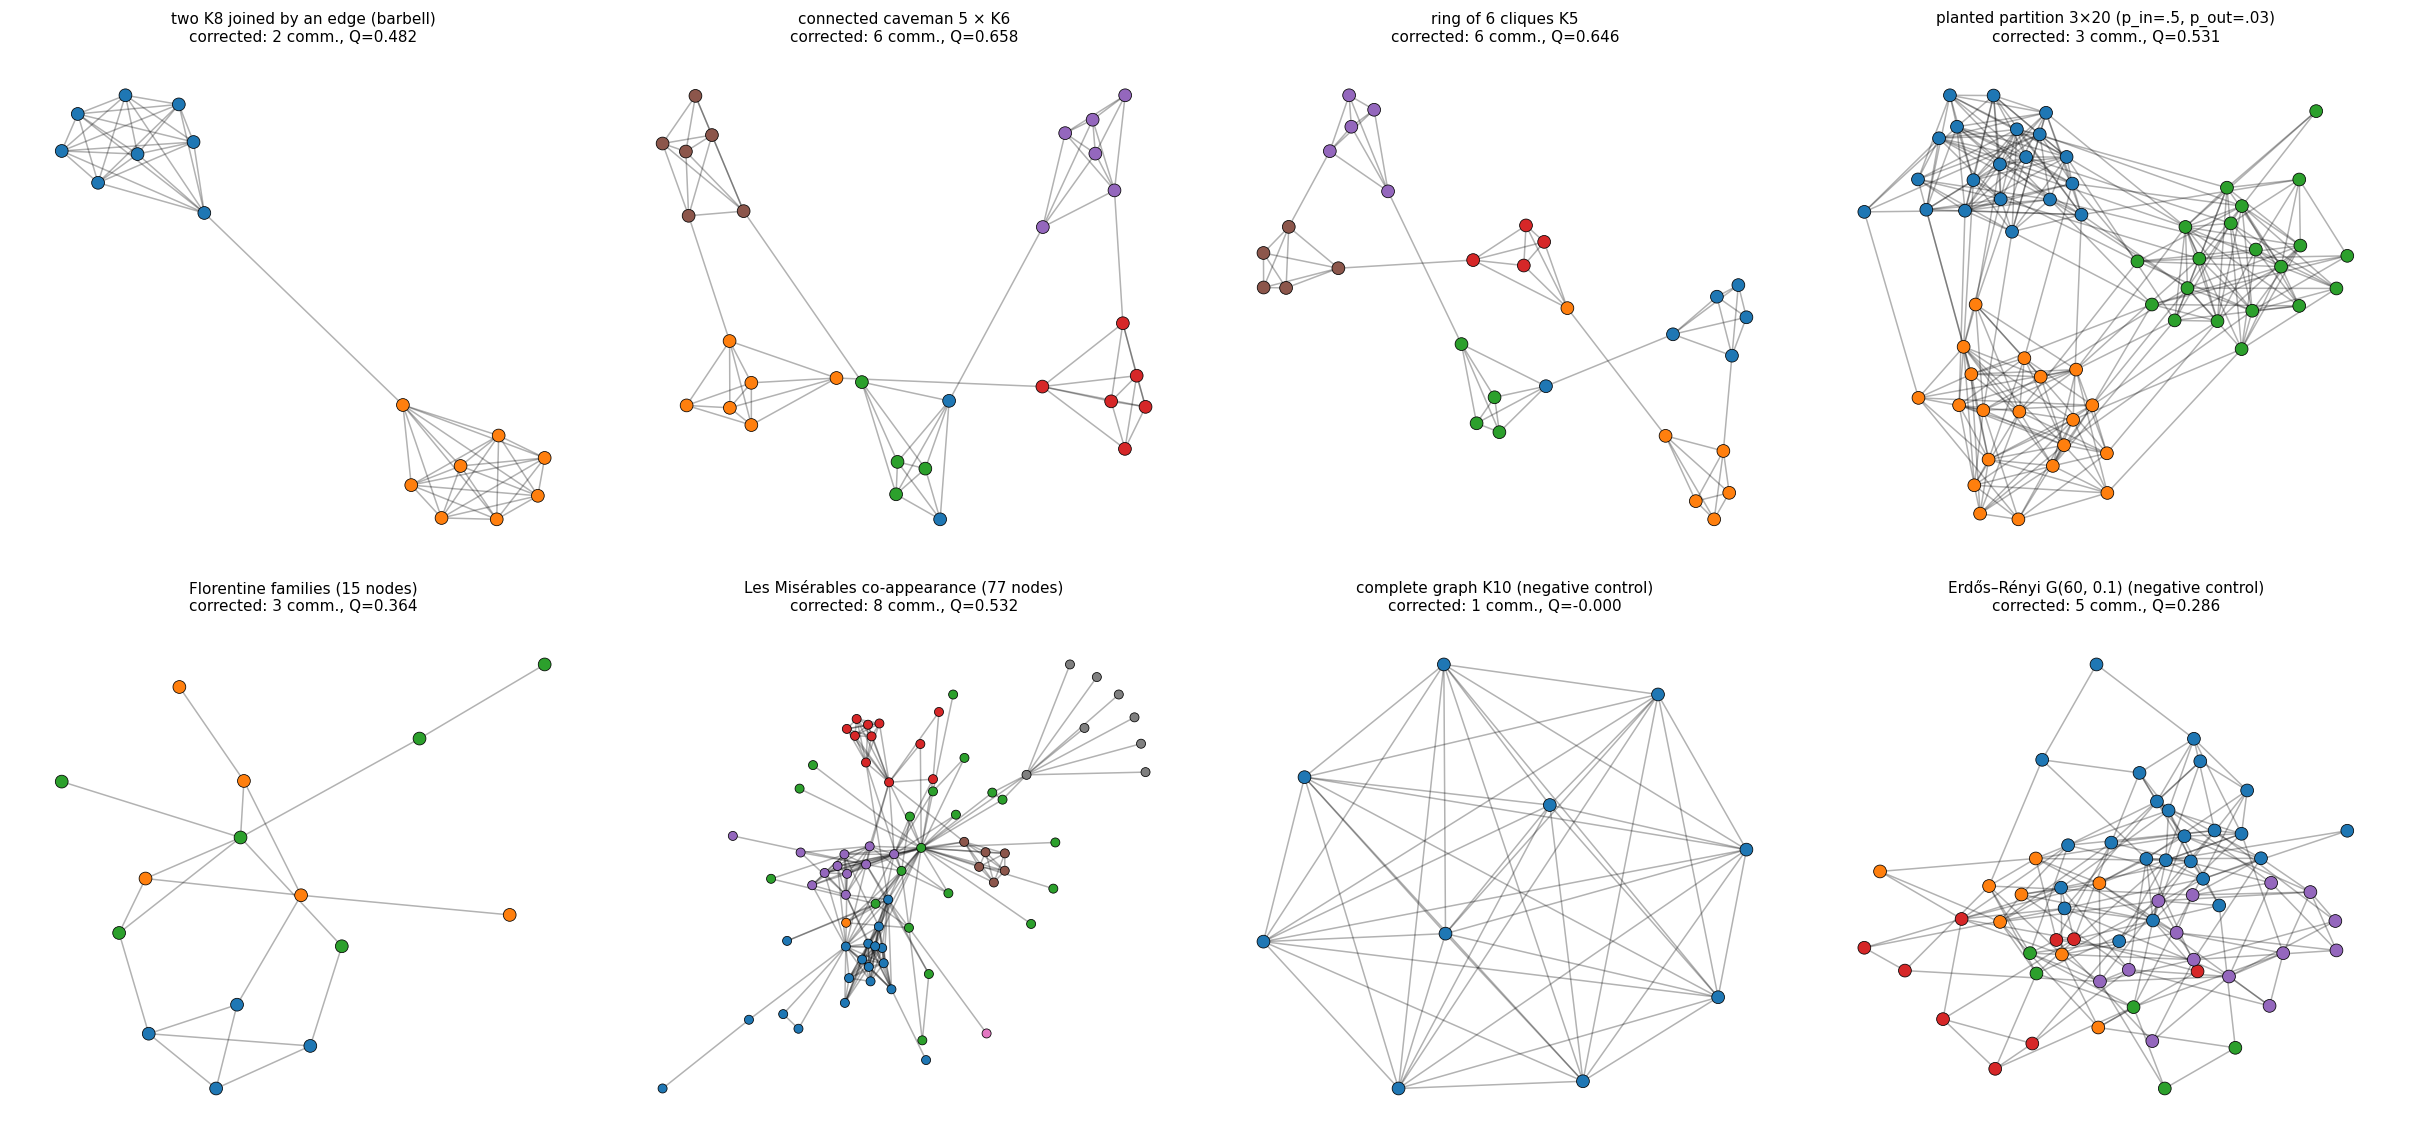

complete graph K10 (negative control): λ1(B) = -0.0000 (≤ 0 → the algorithm correctly refuses to split)
Erdős–Rényi G(60, 0.1) (negative control): λ1(B) = 4.5204 (> 0 → random fluctuations create a positive eigenvalue: modularity > 0 does NOT prove real communities)


In [ ]:
fig, axs = plt.subplots(2, 4, figsize=(22, 10.5)); axs = axs.ravel()
for ax, (name, (Gx, lab, lab_h)) in zip(axs, figs.items()):
    p = nx.spring_layout(Gx, seed=SEED); Ax = nx.to_numpy_array(Gx, weight=None); kx = Ax.sum(1); Bx = Ax - np.outer(kx, kx) / kx.sum()
    for v in Gx: pass
    nx.draw_networkx_edges(Gx, p, ax=ax, alpha=.3)
    nx.draw_networkx_nodes(Gx, p, node_color=[PALETTE[l % 10] for l in lab], node_size=70 if len(Gx) < 70 else 35, edgecolors="k", linewidths=.5, ax=ax)
    ax.set_title(f"{name}\ncorrected: {len(np.unique(lab))} comm., Q={Q_from_labels(Bx, lab, kx.sum()/2):.3f}", fontsize=10); ax.set_axis_off()
plt.tight_layout(); plt.show()

# A closer look at the two negative controls: eigenvalue test
for name in ["complete graph K10 (negative control)", "Erdős–Rényi G(60, 0.1) (negative control)"]:
    Gx = figs[name][0]; Ax = nx.to_numpy_array(Gx, weight=None); kx = Ax.sum(1); Bx = Ax - np.outer(kx, kx) / kx.sum()
    print(f"{name}: λ1(B) = {np.linalg.eigvalsh(Bx)[-1]:.4f}", "(≤ 0 → the algorithm correctly refuses to split)" if np.linalg.eigvalsh(Bx)[-1] <= 1e-9 else
          "(> 0 → random fluctuations create a positive eigenvalue: modularity > 0 does NOT prove real communities)")

         NMI  NMI_sd      Q
p_out                      
0.02   1.000   0.000  0.453
0.05   0.979   0.047  0.392
0.10   0.979   0.047  0.299
0.15   0.838   0.110  0.234
0.20   0.637   0.119  0.170
0.25   0.441   0.187  0.134
0.30   0.126   0.100  0.113


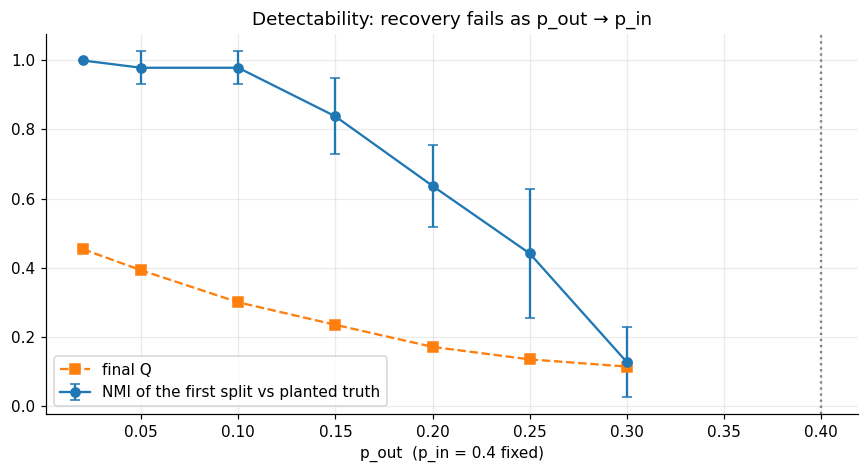

In [ ]:
# Robustness: planted partitions with decreasing contrast.  When p_in - p_out gets small the communities become undetectable.
rows = []
for p_out in [0.02, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3]:
    for rep in range(5):
        Gp = prep(nx.planted_partition_graph(2, 30, .4, p_out, seed=100 + rep)); Ap = nx.to_numpy_array(Gp, weight=None)
        r = recursive_spectral(Ap, "corrected"); truth_p = np.repeat([0, 1], 30)[: len(Gp)]
        first = r["history"][1]["labels"] if len(r["history"]) > 1 else np.zeros(len(Gp), int)
        rows.append({"p_out": p_out, "rep": rep, "NMI of first split": nmi(first, truth_p) if len(np.unique(first)) > 1 else 0.0, "Q": r["history"][-1]["Q"]})
rb = pd.DataFrame(rows).groupby("p_out").agg(NMI=("NMI of first split", "mean"), NMI_sd=("NMI of first split", "std"), Q=("Q", "mean"))
print(rb.round(3).to_string())
fig, ax = plt.subplots(figsize=(8, 4.4)); ax.errorbar(rb.index, rb.NMI, yerr=rb.NMI_sd, fmt="o-", capsize=3, label="NMI of the first split vs planted truth")
ax.plot(rb.index, rb.Q, "s--", label="final Q"); ax.axvline(.4, c="grey", ls=":"); ax.set_xlabel("p_out  (p_in = 0.4 fixed)"); ax.set_title("Detectability: recovery fails as p_out → p_in")
ax.legend(); plt.tight_layout(); plt.show()

## Part 13 — Discussion

*(Numbers below are read from the outputs above; because everything is seeded they are reproduced on every run.)*

### 13.1 What the algorithm found
* **Whole-graph baseline.** The real split has $Q=0.358$ and a random bisection has $Q=-0.024\pm0.049$, so the real split sits about 8 standard deviations above chance, while the minimum-cut split (isolate node 11, one edge) has $Q\approx0$. Cut size alone is useless here; modularity is not.
* **First split (λ₁ = 4.977).** The sign of the leading eigenvector reproduces the real split for **33 of 34 members (97 %)**. The only error is **node 8**, who in reality followed Mr. Hi but has more links into the administrator's side (5 neighbours: 0, 2, 30, 32, 33 — three of them in the administrator's group). The spectral split reaches $Q=0.3715$, i.e. *higher* than the true split (0.3582): the method optimises structure only, whereas Zachary reports that this member had a personal reason to stay with Mr. Hi (he was close to his black-belt test), a non-structural loyalty no graph method can see. A threshold sweep and single-vertex refinement only add $0.0003$ (node 9 moves), so the unmodified sign rule is essentially optimal here (the best of 300 greedy restarts is 0.3718).
* **Further splits.** The handout variant gives 5 communities ($Q=0.409$, ΔQ = +0.3715, +0.0183, +0.0183, +0.0013). The corrected variant gives 4 communities ($Q=0.393$) and rejects a fifth split whose gain would be negative. All final communities are *pure* with respect to the factions except the one containing node 8; the sub-communities correspond to sensible social sub-groups (e.g. the tight group {24, 25, 27, 28, 31} around the administrator's side, and {4, 5, 6, 10, 16} around Mr. Hi). The best modularity any method reached in our comparison is Louvain's $0.4198$ (best of 30 seeds), so recursive bisection (which cannot move nodes once placed) is close to, but not at, the optimum.
* **Diminishing returns.** After the first split, each further split adds only 0.001–0.02 to $Q$; almost all the modular signal is in the two-faction structure, which matches the dominant eigenvalue (λ₁ = 4.98 against λ₂ = 3.04, λ₃ = 2.32).

### 13.2 Which nodes consistently stay central?
| metric | in the top-5 at *every* iteration | comment |
|---|---|---|
| degree centrality | 0, 1, 32, 33 | the two leaders and their closest lieutenants |
| betweenness centrality | 0, 32, 33 | the two leaders are the brokers inside whatever community they end up in |
| closeness centrality | 0, 33 | the only two nodes that reach everybody quickly at every stage |
| clustering coefficient | 7, 12, 14 | *not* hubs: members of small cliques (clustering = 1) |

Averaged over all four metrics and all iterations, the most consistently central nodes are **0 (Mr. Hi, mean rank 7.6)**, then **1 and 33 (8.75)**, 13, 32, 7, 3, 31. Nodes 0 and 33 are the only two that are in the top-5 for degree, betweenness *and* closeness at every iteration; they are central because each is the hub of its own faction, not just because of high degree. (Nodes such as 13, 7 and 8 reach rank 1 on one metric at some iteration, but only briefly, which is why their *worst* rank is much lower — see the table above.) Clustering is the opposite kind of importance: the *least* connected nodes (degree 2–4) have clustering 1, since they sit inside a clique. This is why "central" must always be qualified by the metric: **hub (degree), broker (betweenness), fast spreader (closeness) and clique-member (clustering) are four different roles.**

### 13.3 How community structure changes the metrics
1. **Normalisation by community size inflates raw values.** Degree centrality of node 0 rises from 0.48 (16 of 33 possible neighbours) to 1.00 (it touches all 9 other members of its final community), and its closeness rises from 0.57 to 1.00. The mean of every metric rises with the iteration (mean degree centrality 0.139 → 0.423, mean closeness 0.427 → 0.639) simply because the communities are smaller and denser — this is a *scale effect*, so conclusions must be drawn from **ranks** (Spearman ρ against iteration 0 falls to 0.81 for degree, 0.61 for betweenness, 0.53 for closeness and 0.67 for clustering), not from absolute values.
2. **Betweenness is the most community-sensitive metric.** It measures use as a go-between, and splitting removes the cross-community shortest paths. Node 2 has the 4th-largest whole-graph betweenness (0.144) but only 0.007 inside its community: its brokerage was *between* communities (its participation coefficient is 0.62, with 5 of its 10 links leaving its community). Conversely, nodes 24 and 31 jump to betweenness 0.50 in the 5-node community {24, 25, 27, 28, 31}, where they are the connectors of a small group.
3. **Closeness behaves like betweenness but more smoothly**, and has the lowest rank stability (ρ = 0.53 at the end). Node 11 (degree 1) is isolated by the handout run and its closeness collapses to 0 (convention for a singleton community).
4. **Clustering reveals what a cut destroys.** Node 4 drops from 0.67 to 0 once node 0 lies in another community (its triangle with 0 is cut), whereas nodes 2 and 19 *rise* (2: 0.24 → 0.90, 19: 0.33 → 1.00) because the neighbours that were *not* adjacent to them were left behind. Clustering is the only metric whose ordering is nearly frozen after iteration 3 (ρ = 1.00 between iterations 3 and 4), because the last split moves a single node.
5. **Bridging vs. hubs.** Participation coefficient and global betweenness are positively related (Spearman 0.71), i.e. brokers are exactly the nodes with neighbours in several communities. Yet the highest participation belongs to low-degree nodes (28, 27) — participation says *where* a node's links go, betweenness says *how many paths depend on it*; both are needed. Fifteen nodes (3, 7, 11, 12, 14–18, 20–22, 24, 26, 29) have *all* neighbours in their own community, and 73 % of the edges (57 of 78) are inside communities versus a null-model expectation of about 32 %.

### 13.4 Honest limitations and observations
* **A discrepancy in the handout's stopping rule (Part 7).** $\Delta Q=\frac1{4m}s^\top B^{(C)}s$ is exact only when $\mathbf 1^\top B^{(C)}\mathbf 1=0$, i.e. for the first split. For sub-communities the exact value is $\frac1{4m}(s^\top B^{(C)}s-\mathbf 1^\top B^{(C)}\mathbf 1)$ (Newman's $B^{(g)}$). Numerically the handout formula over-states the gain (e.g. 0.111 predicted versus 0.018 actual at iteration 2), and for tight groups $\lambda_1(B^{(C)})>0$ although no split exists (the four multi-node final communities of the handout run have $\lambda_1(B^{(C)})\in[1.9,2.6]$ with a constant-sign eigenvector, while the corrected matrix gives $\lambda_1\approx0$). We therefore (i) implemented the handout rule as specified, (ii) added two guards (constant sign vector; never accept a split with $\Delta Q\le0$) and (iii) ran the corrected variant alongside. The qualitative conclusions above hold for both runs.
* **Modularity $>0$ does not prove structure.** On an Erdős–Rényi graph with no planted communities the same code finds 5–6 communities with $Q\approx0.29$–$0.31$; only the complete graph is (correctly) refused. Modularity should be compared against a null distribution, as in Part 3.
* **Spectral bisection is greedy.** Nodes are never reassigned; Louvain (which moves nodes) reaches higher $Q$. Modularity maximisation also has a *resolution limit* (Fortunato & Barthélemy, 2007): small cliques may be merged in large graphs.
* **Metric definition.** "Metrics after each split" is interpreted as *within-community* metrics (otherwise nothing changes). Other reasonable choices (e.g. removing the cut edges, or using the community-quotient graph) would give different numbers. Closeness on disconnected communities uses NetworkX's default scaling, and singleton communities are assigned 0.
* **One network, one run.** Karate Club is tiny and is the standard benchmark; the planted-partition experiment in Part 12 shows that recovery degrades as $p_{out}\to p_{in}$ (NMI of the first split: 1.0 at $p_{out}=0.02$, 0.64 at 0.20, 0.13 at 0.30).

## Part 14 — Concept check (exam-style) and references

**Q1. Why is the cut size not a good objective for community detection?** Because the cheapest cuts isolate low-degree nodes (here node 11: cut = 1, $Q\approx0$) and do not say whether the split is better than what a random network with the same degrees would give. Modularity measures *observed − expected* within-group edges.

**Q2. What is the null model and why $k_ik_j/2m$?** The configuration model: each node keeps its $k_i$ stubs and the $2m$ stubs are paired uniformly at random. Node $i$ offers $k_i$ stubs and each lands on a stub of $j$ with probability $k_j/2m$, so $\mathbb E[A_{ij}]=k_ik_j/2m$.

**Q3. Why does $B\mathbf 1=\mathbf 0$ and what does it imply?** $A\mathbf 1=k$ and $k(k^\top\mathbf 1)/2m=k$, so rows of $B$ sum to zero. Hence $0$ is always an eigenvalue of the global $B$ and the trivial partition has $Q=0$.

**Q4. Why is the leading eigenvector the right relaxation?** Rayleigh–Ritz: $\max_{\|s\|=1}s^\top Bs=\lambda_1$, attained at $u_1$. The $\pm1$ constraint is replaced by $\|s\|_2=1$ and the real solution is rounded by sign. The bound $Q\le n\lambda_1/4m$ follows from $\|s\|^2=n$.

**Q5. Why is it enough that $\lambda_1(B^{(C)})\le0$ to stop?** For every $s$, $s^\top B^{(C)}s\le\lambda_1\|s\|^2\le0$, so no split has positive quadratic form. (Subtlety from Part 7: for a *sub*community the exact gain uses $B^{(g)}$; the corrected test $\lambda_1(B^{(g)})\le0$ is the exact criterion.)

**Q6. What does the recursion return and why does Q grow only a little after the first split?** A partition into communities each of which has no positive-gain bisection. Most modular structure is captured by the dominant eigenvector (λ₁ = 4.98 ≫ the next ones), so later splits add 0.001–0.02.

**Q7. Why do the metrics have to be recomputed *within* communities?** On the whole graph they do not depend on the partition. Restricting to the induced subgraph shows a node's local role; ranks (not raw values) must be compared because normalisation uses the community size.

**Q8. Which node does the spectral method misplace and why?** Node 8 — it has more neighbours in the administrator's group than in Mr. Hi's, so any structure-only method puts it on the other side; the real decision was influenced by non-structural factors.

### References
1. M. E. J. Newman (2006). *Modularity and community structure in networks.* PNAS 103(23):8577–8582.
2. W. W. Zachary (1977). *An information flow model for conflict and fission in small groups.* J. Anthropological Research 33(4):452–473.
3. M. E. J. Newman and M. Girvan (2004). *Finding and evaluating community structure in networks.* Phys. Rev. E 69:026113.
4. V. D. Blondel, J.-L. Guillaume, R. Lambiotte, E. Lefebvre (2008). *Fast unfolding of communities in large networks.* J. Stat. Mech. P10008.
5. A. Clauset, M. E. J. Newman, C. Moore (2004). *Finding community structure in very large networks.* Phys. Rev. E 70:066111.
6. S. Fortunato and M. Barthélemy (2007). *Resolution limit in community detection.* PNAS 104(1):36–41.
7. R. Guimerà and L. A. N. Amaral (2005). *Functional cartography of complex metabolic networks.* Nature 433:895–900 (participation coefficient).
8. L. C. Freeman (1977, 1979). Betweenness and centrality measures in social networks; U. Brandes (2001), *A faster algorithm for betweenness centrality*, J. Math. Sociol. 25(2):163–177.
9. A. A. Hagberg, D. A. Schult, P. J. Swart (2008). *Exploring network structure, dynamics, and function using NetworkX.* SciPy 2008.

In [ ]:
# Final self-check: every headline number used in the discussion is re-derived here, so the text cannot silently drift from the code.
H, C = RES["handout"], RES["corrected"]
checks = {
    "B is symmetric with B·1 = 0": np.allclose(B, B.T) and np.abs(B @ np.ones(n)).max() < 1e-10,
    "ground-truth Q ≈ 0.358": abs(Q_from_s(B, truth, m) - 0.3582) < 5e-4,
    "first split recovers 33/34 members": agree == 33 and mis == [8],
    "spectral Q(1st split) ≈ 0.3715": abs(HIST[1]["Q"] - 0.3715) < 5e-4,
    "handout run: 5 communities, Q ≈ 0.4094": len(np.unique(H["labels"])) == 5 and abs(Q_from_labels(B, H["labels"], m) - 0.4094) < 5e-4,
    "corrected run: 4 communities, Q ≈ 0.3934": len(np.unique(C["labels"])) == 4 and abs(Q_from_labels(B, C["labels"], m) - 0.3934) < 5e-4,
    "our Q equals networkx modularity": all(np.isclose(Q_from_labels(B, r["labels"], m), nx.community.modularity(G, [set(np.where(r["labels"] == c)[0]) for c in np.unique(r["labels"])], weight=None)) for r in (H, C)),
    "iteration-0 metrics equal networkx on the whole graph": all(np.allclose(TABLES[nm][0].values, pd.Series(fn(G)).sort_index().values) for nm, fn in METRICS.items()),
    "Q is non-decreasing across accepted splits": all(HIST[i + 1]["Q"] > HIST[i]["Q"] for i in range(len(HIST) - 1)),
}
for name, ok in checks.items(): print(("✔ " if ok else "✘ ") + name)
assert all(checks.values()), "a headline number changed — update the discussion"
print("\nAll checks passed. Notebook finished.")

✔ B is symmetric with B·1 = 0
✔ ground-truth Q ≈ 0.358
✔ first split recovers 33/34 members
✔ spectral Q(1st split) ≈ 0.3715
✔ handout run: 5 communities, Q ≈ 0.4094
✔ corrected run: 4 communities, Q ≈ 0.3934
✔ our Q equals networkx modularity
✔ iteration-0 metrics equal networkx on the whole graph
✔ Q is non-decreasing across accepted splits

All checks passed. Notebook finished.
